<a href="https://colab.research.google.com/github/shizy/cp4282-proj/blob/main/gs_image_codec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploring 3DGS Compression with Image Codecs

A **post-training** pipeline takes a frozen (pruned) 3DGS `.ply`, quantizes it,
places the splats on a $W\times W$ grid with $W=\lceil\sqrt N\rceil$, and stores each attribute group as standard images (PNG / WebP / JPEG / AVIF) plus a small JSON metadata file.`

**Inputs.** A standard INRIA-format `point_cloud.ply` per scene and the NeRF-Synthetic folder (`transforms_test.json`, `test/*.png`, and `transforms_train.json` for pruning).
If none are found, the notebook builds a small **synthetic scene** so every cell still runs end-to-end (ground truth is rendered from a clean version of the synthetic scene; the "checkpoint" is a perturbed copy, so it scores ~30–35 dB like a trained model). Synthetic numbers only check the plumbing — they say nothing about real scenes.

In [ ]:
# Environment setup (runs pip only on Colab; elsewhere install the same packages yourself)
import sys, subprocess
def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
if "google.colab" in sys.modules:
    pip_install("warp-lang", "plyfile", "zstandard", "pillow>=11.3", "scikit-image")
# Optional extras: LPIPS (needs torch) and PLAS sorting for the extra ordering
pip_install("lpips"); pip_install("git+https://github.com/fraunhoferhhi/PLAS.git")

In [ ]:
import os, io, json, time, math, zlib, lzma, itertools, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, features
import warp as wp

try:
    import zstandard as zstd
except ImportError:
    zstd = None

wp.config.quiet = True
wp.init()
DEVICE = "cuda:0" if wp.is_cuda_available() else "cpu"
ON_GPU = DEVICE.startswith("cuda")
print("Warp", wp.config.version, "| device:", DEVICE, "| AVIF:", features.check("avif"), "| WebP:", features.check("webp"))

Warp 1.19.0 | device: cuda:0 | AVIF: True | WebP: True


## 1. Configuration

In [ ]:
CFG = dict(
    scene="lego",
    scenes=["lego", "materials", "ship"],                          # §15
    ply_path="data/nerf_synthetic/{scene}/{scene}.ply",
    data_dir="data/nerf_synthetic/{scene}",
    white_bg=True,
    res_scale=1.0 if ON_GPU else 0.25,       # 800px -> 200px on CPU
    n_eval_views=None if ON_GPU else 25,     # final evaluation (None = all 200)
    n_sweep_views=40 if ON_GPU else 8,       # views used inside sweeps
    prune_keep=None,                         # e.g. 0.5 keeps the 50% most important splats; None if checkpoint is already pruned
    n_prune_views=50,
    shN_clip_pct=0.0,                        # robust range for SH rest (0 = pure min/max, as in the proposal)
    psnr_budget_db=0.5,
    out_dir="out",
    save_images=True,
    # synthetic fallback
    synthetic_if_missing=True,
    synth_n=30_000, synth_res=200, synth_test_views=60, synth_train_views=30,
)
os.makedirs(CFG["out_dir"], exist_ok=True)

def scene_paths(scene):
    return CFG["ply_path"].format(scene=scene), CFG["data_dir"].format(scene=scene)

## 2. Gaussian model I/O

In [ ]:
SH_C0 = 0.28209479177387814

def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

def load_ply(path):
    """INRIA 3DGS ply -> dict(means, sh0, shN[N,K,3], opacity(logit), scales(log), quats(wxyz))."""
    from plyfile import PlyData
    v = PlyData.read(path)["vertex"]
    names = v.data.dtype.names
    g = lambda n: np.asarray(v[n], dtype=np.float32)
    rest = sorted([n for n in names if n.startswith("f_rest_")], key=lambda s: int(s.split("_")[-1]))
    N = len(v.data); K = len(rest) // 3
    shN = (np.stack([g(n) for n in rest], 1).reshape(N, 3, K).transpose(0, 2, 1)
           if K else np.zeros((N, 0, 3), np.float32))
    q = np.stack([g(f"rot_{i}") for i in range(4)], 1)
    q /= np.linalg.norm(q, axis=1, keepdims=True) + 1e-12
    return dict(means=np.stack([g("x"), g("y"), g("z")], 1),
                sh0=np.stack([g(f"f_dc_{i}") for i in range(3)], 1),
                shN=np.ascontiguousarray(shN),
                opacity=g("opacity"),
                scales=np.stack([g(f"scale_{i}") for i in range(3)], 1),
                quats=q.astype(np.float32))

def save_ply(m, path):
    """Write the standard uncompressed float32 3DGS ply (used for the 'raw .ply' size)."""
    from plyfile import PlyData, PlyElement
    N, K = len(m["means"]), m["shN"].shape[1]
    attrs = (["x", "y", "z", "nx", "ny", "nz"] + [f"f_dc_{i}" for i in range(3)] +
             [f"f_rest_{i}" for i in range(3 * K)] + ["opacity"] +
             [f"scale_{i}" for i in range(3)] + [f"rot_{i}" for i in range(4)])
    cols = np.concatenate([m["means"], np.zeros((N, 3), np.float32), m["sh0"],
                           m["shN"].transpose(0, 2, 1).reshape(N, -1), m["opacity"][:, None],
                           m["scales"], m["quats"]], 1).astype(np.float32)
    el = np.empty(N, dtype=[(a, "f4") for a in attrs])
    el[:] = list(map(tuple, cols))
    PlyData([PlyElement.describe(el, "vertex")]).write(path)
    return os.path.getsize(path)

def subset(m, idx):
    return {k: np.ascontiguousarray(v[idx]) for k, v in m.items()}

def n_splats(m): return len(m["means"])

## 3. Cameras (NeRF-Synthetic / Blender convention)

In [ ]:
def load_split(data_dir, split, res_scale=1.0, white_bg=True, max_views=None, load_images=True):
    meta = json.load(open(os.path.join(data_dir, f"transforms_{split}.json")))
    frames = meta["frames"]
    if max_views is not None and max_views < len(frames):
        frames = [frames[i] for i in np.linspace(0, len(frames) - 1, max_views).round().astype(int)]
    bg = np.ones(3, np.float32) if white_bg else np.zeros(3, np.float32)
    cams, gts = [], []
    for fr in frames:
        fp = os.path.join(data_dir, fr["file_path"])
        if not fp.endswith(".png"): fp += ".png"
        if load_images:
            im = Image.open(fp).convert("RGBA")
            W0, H0 = im.size
            if res_scale != 1.0:
                im = im.resize((round(W0 * res_scale), round(H0 * res_scale)), Image.LANCZOS)
            a = np.asarray(im, np.float32) / 255.0
            gts.append(a[..., :3] * a[..., 3:] + bg * (1 - a[..., 3:]))
            W, H = im.size
        else:
            W = H = round(800 * res_scale)
        fx = 0.5 * W / math.tan(0.5 * meta["camera_angle_x"])
        c2w = np.array(fr["transform_matrix"], np.float64)
        c2w[:3, 1:3] *= -1                      # OpenGL -> OpenCV
        w2c = np.linalg.inv(c2w)
        cams.append(dict(R=w2c[:3, :3].astype(np.float32), t=w2c[:3, 3].astype(np.float32),
                         campos=c2w[:3, 3].astype(np.float32), fx=fx, fy=fx, cx=W / 2, cy=H / 2, W=W, H=H))
    return cams, gts, bg

## 2b. Forward 3DGS rasterizer in Warp
Standard tile-based EWA splatting (Kerbl et al. 2023), forward only:
1. **preprocess** kernel: cull, 3D covariance $R S S^\top R^\top$, EWA projection (+0.3 low-pass), conic, 3σ radius, tile rectangle, SH (deg ≤ 3) colour;
2. stable radix sort by depth, duplicate per touched tile (exclusive scan), stable radix sort by tile id ⇒ per-tile front-to-back lists;
3. **render** kernel: one thread per pixel, front-to-back α-compositing with early termination.

The render kernel can also accumulate per-splat contribution $\sum \alpha T$ (used for importance pruning).

In [ ]:
TILE_SIZE = wp.constant(16)

# Spherical Harmonics (SH) basis constants for degrees 0 to 3
# These are normalization factors that are precomputed as "compile-time" constants
SH_C0 = wp.constant(0.28209479177387814)
SH_C1 = wp.constant(0.4886025119029199)

SH_C2_0 = wp.constant(1.0925484305920792)
SH_C2_1 = wp.constant(-1.0925484305920792)
SH_C2_2 = wp.constant(0.31539156525252005)
SH_C2_3 = wp.constant(-1.0925484305920792)
SH_C2_4 = wp.constant(0.5462742152960396)

SH_C3_0 = wp.constant(-0.5900435899266435)
SH_C3_1 = wp.constant(2.890611442640554)
SH_C3_2 = wp.constant(-0.4570457994644658)
SH_C3_3 = wp.constant(0.3731763325901154)
SH_C3_4 = wp.constant(-0.4570457994644658)
SH_C3_5 = wp.constant(1.445305721320277)
SH_C3_6 = wp.constant(-0.5900435899266435)


@wp.func
def quat_to_rotmat(quat: wp.vec4) -> wp.mat33:
    """Convert a normalized quaternion (w, x, y, z) into a 3x3 rotation matrix."""
    w = quat[0]
    x = quat[1]
    y = quat[2]
    z = quat[3]
    return wp.mat33(
        1.0 - 2.0 * (y * y + z * z), 2.0 * (x * y - w * z),       2.0 * (x * z + w * y),
        2.0 * (x * y + w * z),       1.0 - 2.0 * (x * x + z * z), 2.0 * (y * z - w * x),
        2.0 * (x * z - w * y),       2.0 * (y * z + w * x),       1.0 - 2.0 * (x * x + y * y)
    )


@wp.func
def eval_sh(
    sh_coeffs: wp.array2d(dtype=wp.vec3),
    splat_idx: int,
    sh_degree: int,
    view_dir: wp.vec3
) -> wp.vec3:
    """Evaluate Spherical Harmonics (up to degree 3) for a given viewing direction."""
    color = SH_C0 * sh_coeffs[splat_idx, 0]

    if sh_degree > 0:
        x = view_dir[0]
        y = view_dir[1]
        z = view_dir[2]
        color = (
            color
            - SH_C1 * y * sh_coeffs[splat_idx, 1]
            + SH_C1 * z * sh_coeffs[splat_idx, 2]
            - SH_C1 * x * sh_coeffs[splat_idx, 3]
        )

        if sh_degree > 1:
            xx = x * x
            yy = y * y
            zz = z * z
            color = (
                color
                + SH_C2_0 * x * y * sh_coeffs[splat_idx, 4]
                + SH_C2_1 * y * z * sh_coeffs[splat_idx, 5]
                + SH_C2_2 * (2.0 * zz - xx - yy) * sh_coeffs[splat_idx, 6]
                + SH_C2_3 * x * z * sh_coeffs[splat_idx, 7]
                + SH_C2_4 * (xx - yy) * sh_coeffs[splat_idx, 8]
            )

            if sh_degree > 2:
                color = (
                    color
                    + SH_C3_0 * y * (3.0 * xx - yy) * sh_coeffs[splat_idx, 9]
                    + SH_C3_1 * x * y * z * sh_coeffs[splat_idx, 10]
                    + SH_C3_2 * y * (4.0 * zz - xx - yy) * sh_coeffs[splat_idx, 11]
                    + SH_C3_3 * z * (2.0 * zz - 3.0 * xx - 3.0 * yy) * sh_coeffs[splat_idx, 12]
                    + SH_C3_4 * x * (4.0 * zz - xx - yy) * sh_coeffs[splat_idx, 13]
                    + SH_C3_5 * z * (xx - yy) * sh_coeffs[splat_idx, 14]
                    + SH_C3_6 * x * (xx - 3.0 * yy) * sh_coeffs[splat_idx, 15]
                )

    return color + wp.vec3(0.5, 0.5, 0.5)


@wp.kernel
def preprocess_kernel(
    means_3d: wp.array(dtype=wp.vec3),
    scales_3d: wp.array(dtype=wp.vec3),
    quats: wp.array(dtype=wp.vec4),
    opacities: wp.array(dtype=float),
    sh_coeffs: wp.array2d(dtype=wp.vec3),
    sh_degree: int,
    cam_rot: wp.mat33,
    cam_trans: wp.vec3,
    cam_pos: wp.vec3,
    fx: float,
    fy: float,
    cx: float,
    cy: float,
    img_w: int,
    img_h: int,
    num_tiles_x: int,
    num_tiles_y: int,
    # Outputs:
    means_2d: wp.array(dtype=wp.vec2),
    conics: wp.array(dtype=wp.vec3),
    colors_rgb: wp.array(dtype=wp.vec3),
    alphas: wp.array(dtype=float),
    depths: wp.array(dtype=float),
    tile_bounds: wp.array(dtype=wp.vec4i),
    num_tiles_touched: wp.array(dtype=int)
):
    splat_idx = wp.tid()
    num_tiles_touched[splat_idx] = 0
    depths[splat_idx] = 1.0e30

    # 1. Transform 3D Gaussian center from world space to camera space
    pos_world = means_3d[splat_idx]
    pos_cam = cam_rot * pos_world + cam_trans
    depth_z = pos_cam[2]

    # Near-plane frustum culling
    if depth_z < 0.2:
        return

    # 2. Compute 3D world covariance matrix: Sigma_3d = R * S * S^T * R^T
    scale = scales_3d[splat_idx]
    rot_scale_mat = quat_to_rotmat(wp.normalize(quats[splat_idx])) * wp.diag(scale)
    cov_3d = rot_scale_mat * wp.transpose(rot_scale_mat)

    # 3. EWA Splatting: project 3D covariance to 2D image space via affine Jacobian J
    # Clamp off-frustum coordinates to prevent extreme Jacobian distortion
    tan_fov_x = 0.5 * float(img_w) / fx
    tan_fov_y = 0.5 * float(img_h) / fy
    lim_x = 1.3 * tan_fov_x
    lim_y = 1.3 * tan_fov_y
    clamped_x = wp.clamp(pos_cam[0] / depth_z, -lim_x, lim_x) * depth_z
    clamped_y = wp.clamp(pos_cam[1] / depth_z, -lim_y, lim_y) * depth_z

    proj_jacobian = wp.mat33(
        fx / depth_z, 0.0,          -fx * clamped_x / (depth_z * depth_z),
        0.0,          fy / depth_z, -fy * clamped_y / (depth_z * depth_z),
        0.0,          0.0,          0.0
    )
    proj_transform = proj_jacobian * cam_rot
    cov_2d = proj_transform * cov_3d * wp.transpose(proj_transform)

    # Add 0.3 low-pass filter to diagonal to ensure at least ~1 pixel screen coverage
    cov_xx = cov_2d[0, 0] + 0.3
    cov_xy = cov_2d[0, 1]
    cov_yy = cov_2d[1, 1] + 0.3

    det = cov_xx * cov_yy - cov_xy * cov_xy
    if det <= 0.0:
        return

    # 4. Compute 3-sigma bounding radius in pixels from the largest eigenvalue of cov_2d
    half_trace = 0.5 * (cov_xx + cov_yy)
    max_eigenval = half_trace + wp.sqrt(wp.max(0.1, half_trace * half_trace - det))
    radius_px = wp.ceil(3.0 * wp.sqrt(max_eigenval))

    # 5. Project 3D center to 2D pixel coordinates and find overlapping 16x16 tiles
    pixel_x = fx * pos_cam[0] / depth_z + cx - 0.5
    pixel_y = fy * pos_cam[1] / depth_z + cy - 0.5

    tile_min_x = wp.clamp(int(wp.floor((pixel_x - radius_px) / float(TILE_SIZE))), 0, num_tiles_x)
    tile_max_x = wp.clamp(int(wp.floor((pixel_x + radius_px + float(TILE_SIZE) - 1.0) / float(TILE_SIZE))), 0, num_tiles_x)
    tile_min_y = wp.clamp(int(wp.floor((pixel_y - radius_px) / float(TILE_SIZE))), 0, num_tiles_y)
    tile_max_y = wp.clamp(int(wp.floor((pixel_y + radius_px + float(TILE_SIZE) - 1.0) / float(TILE_SIZE))), 0, num_tiles_y)

    tiles_count = (tile_max_x - tile_min_x) * (tile_max_y - tile_min_y)
    if tiles_count <= 0:
        return

    # 6. Evaluate view-dependent SH color and store 2D conic (inverse of 2D covariance)
    view_dir = wp.normalize(pos_world - cam_pos)
    raw_color = eval_sh(sh_coeffs, splat_idx, sh_degree, view_dir)

    colors_rgb[splat_idx] = wp.vec3(
        wp.max(raw_color[0], 0.0),
        wp.max(raw_color[1], 0.0),
        wp.max(raw_color[2], 0.0)
    )
    means_2d[splat_idx] = wp.vec2(pixel_x, pixel_y)
    conics[splat_idx] = wp.vec3(cov_yy / det, -cov_xy / det, cov_xx / det)
    alphas[splat_idx] = opacities[splat_idx]
    depths[splat_idx] = depth_z
    tile_bounds[splat_idx] = wp.vec4i(tile_min_x, tile_min_y, tile_max_x, tile_max_y)
    num_tiles_touched[splat_idx] = tiles_count


@wp.kernel
def gather_int(
    src: wp.array(dtype=int),
    indices: wp.array(dtype=int),
    dst: wp.array(dtype=int)
):
    idx = wp.tid()
    dst[idx] = src[indices[idx]]


@wp.kernel
def iota_kernel(arr: wp.array(dtype=int)):
    idx = wp.tid()
    arr[idx] = idx


@wp.kernel
def duplicate_per_tile_kernel(
    depth_sorted_splat_ids: wp.array(dtype=int),
    instance_offsets: wp.array(dtype=int),
    tile_bounds: wp.array(dtype=wp.vec4i),
    num_tiles_touched: wp.array(dtype=int),
    num_tiles_x: int,
    # Outputs:
    out_tile_ids: wp.array(dtype=int),
    out_splat_ids: wp.array(dtype=int)
):
    """Emit (tile_id, splat_id) pairs for every tile overlapped by each Gaussian."""
    sort_rank = wp.tid()
    splat_id = depth_sorted_splat_ids[sort_rank]

    if num_tiles_touched[splat_id] == 0:
        return

    write_idx = instance_offsets[sort_rank]
    bounds = tile_bounds[splat_id]  # (tile_min_x, tile_min_y, tile_max_x, tile_max_y)

    for tile_y in range(bounds[1], bounds[3]):
        for tile_x in range(bounds[0], bounds[2]):
            out_tile_ids[write_idx] = tile_y * num_tiles_x + tile_x
            out_splat_ids[write_idx] = splat_id
            write_idx += 1


@wp.kernel
def find_tile_ranges_kernel(
    sorted_tile_ids: wp.array(dtype=int),
    num_instances: int,
    # Outputs:
    tile_range_start: wp.array(dtype=int),
    tile_range_end: wp.array(dtype=int)
):
    """Identify the start and end indices for each tile's Gaussian list after sorting by tile_id."""
    instance_idx = wp.tid()
    tile_id = sorted_tile_ids[instance_idx]

    if instance_idx == 0:
        tile_range_start[tile_id] = 0
    elif sorted_tile_ids[instance_idx - 1] != tile_id:
        tile_range_start[tile_id] = instance_idx

    if instance_idx == num_instances - 1:
        tile_range_end[tile_id] = num_instances
    elif sorted_tile_ids[instance_idx + 1] != tile_id:
        tile_range_end[tile_id] = instance_idx + 1


@wp.kernel
def render_kernel(
    tile_range_start: wp.array(dtype=int),
    tile_range_end: wp.array(dtype=int),
    sorted_splat_ids: wp.array(dtype=int),
    num_tiles_x: int,
    means_2d: wp.array(dtype=wp.vec2),
    conics: wp.array(dtype=wp.vec3),
    colors_rgb: wp.array(dtype=wp.vec3),
    alphas: wp.array(dtype=float),
    bg_color: wp.vec3,
     accumulate_importance: int,
    importance_scores: wp.array(dtype=float),
    # Outputs:
    out_image: wp.array2d(dtype=wp.vec3),
    out_alpha: wp.array2d(dtype=float)
):
    """Per-pixel front-to-back alpha compositing across the pixel's tile list."""
    pixel_y, pixel_x = wp.tid()
    tile_id = (pixel_y / TILE_SIZE) * num_tiles_x + (pixel_x / TILE_SIZE)

    transmittance = float(1.0)
    accum_color = wp.vec3(0.0, 0.0, 0.0)
    px_pos = wp.vec2(float(pixel_x), float(pixel_y))

    for instance_idx in range(tile_range_start[tile_id], tile_range_end[tile_id]):
        splat_id = sorted_splat_ids[instance_idx]
        offset_xy = means_2d[splat_id] - px_pos
        conic = conics[splat_id]

        # Evaluate 2D Gaussian exponent: -0.5 * (offset^T * Conic * offset)
        exponent = (
            -0.5 * (conic[0] * offset_xy[0] * offset_xy[0] + conic[2] * offset_xy[1] * offset_xy[1])
            - conic[1] * offset_xy[0] * offset_xy[1]
        )
        if exponent > 0.0:
            continue

        splat_alpha = wp.min(0.99, alphas[splat_id] * wp.exp(exponent))
        if splat_alpha < 1.0 / 255.0:
            continue

        next_transmittance = transmittance * (1.0 - splat_alpha)
        if next_transmittance < 0.0001:
            break  # Early ray termination once pixel is saturated

        weight = splat_alpha * transmittance
        accum_color = accum_color + colors_rgb[splat_id] * weight

        if accumulate_importance != 0:
            wp.atomic_add(importance_scores, splat_id, weight)

        transmittance = next_transmittance

    out_image[pixel_y, pixel_x] = accum_color + bg_color * transmittance
    out_alpha[pixel_y, pixel_x] = 1.0 - transmittance


def to_device(model):
    """Activate Gaussian parameters (exp scales, sigmoid opacity, normalized quats) and upload to Warp."""
    sh_all = np.concatenate([model["sh0"][:, None, :], model["shN"]], axis=1).astype(np.float32)
    norm_quats = model["quats"] / (np.linalg.norm(model["quats"], axis=1, keepdims=True) + 1e-12)
    sh_degree = int(round(math.sqrt(sh_all.shape[1]))) - 1

    return dict(
        N=n_splats(model),
        deg=sh_degree,
        means=wp.array(model["means"], dtype=wp.vec3, device=DEVICE),
        scales=wp.array(np.exp(model["scales"]).astype(np.float32), dtype=wp.vec3, device=DEVICE),
        quats=wp.array(norm_quats.astype(np.float32), dtype=wp.vec4, device=DEVICE),
        opac=wp.array(sigmoid(model["opacity"]).astype(np.float32), dtype=float, device=DEVICE),
        sh=wp.array(sh_all, dtype=wp.vec3, device=DEVICE)
    )


def render(device_model, cam, bg_color, importance=None):
    """Render one camera view. Returns (H, W, 3) float RGB image and (H, W) float alpha mask."""
    num_splats = device_model["N"]
    img_w, img_h = cam["W"], cam["H"]
    num_tiles_x = (img_w + 15) // 16
    num_tiles_y = (img_h + 15) // 16
    num_tiles_total = num_tiles_x * num_tiles_y

    # Allocate per-splat buffers for the preprocess pass
    means_2d = wp.zeros(num_splats, dtype=wp.vec2, device=DEVICE)
    conics = wp.zeros(num_splats, dtype=wp.vec3, device=DEVICE)
    colors_rgb = wp.zeros(num_splats, dtype=wp.vec3, device=DEVICE)
    alphas = wp.zeros(num_splats, dtype=float, device=DEVICE)
    depths = wp.zeros(num_splats, dtype=float, device=DEVICE)
    tile_bounds = wp.zeros(num_splats, dtype=wp.vec4i, device=DEVICE)
    num_tiles_touched = wp.zeros(num_splats, dtype=int, device=DEVICE)

    # Step 1: Project 3D Gaussians to 2D screen space and evaluate SH colors
    wp.launch(
        preprocess_kernel,
        dim=num_splats,
        device=DEVICE,
        inputs=[
            device_model["means"], device_model["scales"], device_model["quats"],
            device_model["opac"], device_model["sh"], device_model["deg"],
            wp.mat33(cam["R"]), wp.vec3(cam["t"]), wp.vec3(cam["campos"]),
            float(cam["fx"]), float(cam["fy"]), float(cam["cx"]), float(cam["cy"]),
            img_w, img_h, num_tiles_x, num_tiles_y
        ],
        outputs=[means_2d, conics, colors_rgb, alphas, depths, tile_bounds, num_tiles_touched]
    )

    # Step 2: Sort Gaussians front-to-back by depth
    # Note: Warp's radix_sort_pairs requires buffers of size 2 * N for ping-pong storage
    depth_keys = wp.empty(2 * num_splats, dtype=float, device=DEVICE)
    wp.copy(depth_keys, depths, count=num_splats)
    depth_sorted_splat_ids = wp.empty(2 * num_splats, dtype=int, device=DEVICE)
    wp.launch(iota_kernel, dim=num_splats, inputs=[depth_sorted_splat_ids], device=DEVICE)
    wp.utils.radix_sort_pairs(depth_keys, depth_sorted_splat_ids, num_splats)

    # Step 3: Compute prefix sum of touched tiles in depth-sorted order
    touched_tiles_sorted = wp.zeros(num_splats, dtype=int, device=DEVICE)
    wp.launch(
        gather_int,
        dim=num_splats,
        inputs=[num_tiles_touched, depth_sorted_splat_ids, touched_tiles_sorted],
        device=DEVICE
    )
    instance_offsets = wp.zeros(num_splats, dtype=int, device=DEVICE)
    wp.utils.array_scan(touched_tiles_sorted, instance_offsets, inclusive=False)

    # Total number of (tile_id, splat_id) pairs across the entire screen
    num_instances = int(
        instance_offsets[num_splats - 1 : num_splats].numpy()[0]
        + touched_tiles_sorted[num_splats - 1 : num_splats].numpy()[0]
    )

    out_image = wp.empty((img_h, img_w), dtype=wp.vec3, device=DEVICE)
    out_alpha = wp.empty((img_h, img_w), dtype=float, device=DEVICE)
    tile_range_start = wp.zeros(num_tiles_total, dtype=int, device=DEVICE)
    tile_range_end = wp.zeros(num_tiles_total, dtype=int, device=DEVICE)
    sorted_splat_ids = wp.empty(max(2 * num_instances, 2), dtype=int, device=DEVICE)

    if num_instances > 0:
        # Step 4: Duplicate each Gaussian for every tile it overlaps (in front-to-back order)
        sorted_tile_ids = wp.empty(2 * num_instances, dtype=int, device=DEVICE)
        wp.launch(
            duplicate_per_tile_kernel,
            dim=num_splats,
            inputs=[
                depth_sorted_splat_ids, instance_offsets, tile_bounds,
                num_tiles_touched, num_tiles_x, sorted_tile_ids, sorted_splat_ids
            ],
            device=DEVICE
        )

        # Step 5: Stable radix sort by tile_id so each tile gets a contiguous front-to-back list
        wp.utils.radix_sort_pairs(sorted_tile_ids, sorted_splat_ids, num_instances)
        wp.launch(
            find_tile_ranges_kernel,
            dim=num_instances,
            inputs=[sorted_tile_ids, num_instances, tile_range_start, tile_range_end],
            device=DEVICE
        )

    # Step 6: Rasterize tiles in parallel (one thread per pixel)
    importance_buf = importance if importance is not None else wp.zeros(1, dtype=float, device=DEVICE)
    wp.launch(
        render_kernel,
        dim=(img_h, img_w),
        device=DEVICE,
        inputs=[
            tile_range_start, tile_range_end, sorted_splat_ids, num_tiles_x,
            means_2d, conics, colors_rgb, alphas, wp.vec3(bg_color),
            int(importance is not None), importance_buf
        ],
        outputs=[out_image, out_alpha]
    )

    return out_image.numpy(), out_alpha.numpy()

### Metrics and evaluation

In [ ]:
from skimage.metrics import structural_similarity
try:
    import torch, lpips
    _lpips = lpips.LPIPS(net="vgg", verbose=False).eval()
    _lpips_dev = "cuda" if torch.cuda.is_available() else "cpu"; _lpips.to(_lpips_dev)
except Exception:
    _lpips = None

def psnr(a, b):
    return float(-10 * np.log10(np.mean((np.clip(a, 0, 1) - b) ** 2) + 1e-12))

def lpips_score(a, b):
    if _lpips is None: return float("nan")
    t = lambda x: torch.from_numpy(np.clip(x, 0, 1)).permute(2, 0, 1)[None].float().to(_lpips_dev) * 2 - 1
    with torch.no_grad():
        return float(_lpips(t(a), t(b)).item())

def evaluate(model, cams, gts, bg, n_views=None, full=False, keep_views=()):
    """Mean PSNR (+ SSIM/LPIPS if full) over evenly spaced views. Also returns per-view PSNR.
    keep_views: camera indices whose renders are returned in out["images"] (dict index -> image).
    Keep this small: one 800x800 float render is ~7.7 MB, so keeping every view of every config exhausts RAM."""
    dm = to_device(model)
    idx = range(len(cams)) if n_views is None else np.linspace(0, len(cams) - 1, min(n_views, len(cams))).round().astype(int)
    keep_views = set(int(v) for v in keep_views)
    res, imgs, views = dict(psnr=[], ssim=[], lpips=[]), {}, []
    t0 = time.time()
    for i in idx:
        img, _ = render(dm, cams[i], bg)
        res["psnr"].append(psnr(img, gts[i]))
        if full:
            res["ssim"].append(structural_similarity(np.clip(img, 0, 1), gts[i], channel_axis=2, data_range=1.0))
            res["lpips"].append(lpips_score(img, gts[i]))
        views.append(int(i))
        if int(i) in keep_views: imgs[int(i)] = img
    out = {k: float(np.mean(v)) if len(v) else float("nan") for k, v in res.items()}
    out["sec_per_view"] = (time.time() - t0) / len(idx)
    out["views"], out["psnr_per_view"] = views, res["psnr"]
    if keep_views: out["images"] = imgs
    return out

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 62.8MB/s]


### Synthetic fallback scene
Only used when no checkpoint / dataset is found: Gaussians on textured surfaces (sphere, box, torus) with surface-aligned anisotropic scales,
random in-plane rotations, smooth view-dependent SH, written in shuffled order (like a real `.ply`). Test images are rendered from the float model
and written in the Blender format so the normal loading path is exercised.

In [ ]:
def mat_to_quat(Rm):
    """Batched rotation matrix -> quaternion (w,x,y,z)."""
    Rm = np.asarray(Rm, np.float64).reshape(-1, 3, 3)
    q = np.empty((len(Rm), 4))
    tr = Rm[:, 0, 0] + Rm[:, 1, 1] + Rm[:, 2, 2]
    for i, R in enumerate(Rm):
        if tr[i] > 0:
            s = math.sqrt(tr[i] + 1.0) * 2
            q[i] = [0.25 * s, (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s]
        elif R[0, 0] > R[1, 1] and R[0, 0] > R[2, 2]:
            s = math.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2]) * 2
            q[i] = [(R[2, 1] - R[1, 2]) / s, 0.25 * s, (R[0, 1] + R[1, 0]) / s, (R[0, 2] + R[2, 0]) / s]
        elif R[1, 1] > R[2, 2]:
            s = math.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2]) * 2
            q[i] = [(R[0, 2] - R[2, 0]) / s, (R[0, 1] + R[1, 0]) / s, 0.25 * s, (R[1, 2] + R[2, 1]) / s]
        else:
            s = math.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1]) * 2
            q[i] = [(R[1, 0] - R[0, 1]) / s, (R[0, 2] + R[2, 0]) / s, (R[1, 2] + R[2, 1]) / s, 0.25 * s]
    return q / np.linalg.norm(q, axis=1, keepdims=True)

def quat_to_mat_np(q):
    q = q / np.linalg.norm(q, axis=-1, keepdims=True)
    w, x, y, z = q[..., 0], q[..., 1], q[..., 2], q[..., 3]
    return np.stack([1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y),
                     2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x),
                     2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)], -1).reshape(q.shape[:-1] + (3, 3))

def make_synthetic_model(n, seed=0):
    rng = np.random.default_rng(seed)
    kinds = rng.choice(3, n, p=[0.35, 0.35, 0.3])
    P = np.zeros((n, 3)); Nn = np.zeros((n, 3))
    # sphere
    k = kinds == 0; m = k.sum()
    d = rng.normal(size=(m, 3)); d /= np.linalg.norm(d, axis=1, keepdims=True)
    P[k] = d * 0.45 + [0.45, 0.0, 0.25]; Nn[k] = d
    # box surface
    k = kinds == 1; m = k.sum()
    face = rng.integers(0, 6, m); ax = face // 2; sgn = np.where(face % 2 == 0, 1.0, -1.0)
    p = rng.uniform(-1, 1, (m, 3)); p[np.arange(m), ax] = sgn
    nrm = np.zeros((m, 3)); nrm[np.arange(m), ax] = sgn
    P[k] = p * [0.4, 0.4, 0.25] + [-0.45, 0.1, -0.1]; Nn[k] = nrm
    # torus
    k = kinds == 2; m = k.sum()
    u, v = rng.uniform(0, 2 * np.pi, m), rng.uniform(0, 2 * np.pi, m)
    Rt, rt = 0.55, 0.12
    c = np.stack([np.cos(u), np.sin(u), 0 * u], 1)
    nrm = c * np.cos(v)[:, None] + np.array([0, 0, 1.0]) * np.sin(v)[:, None]
    P[k] = c * Rt + nrm * rt + [0, 0, -0.45]; Nn[k] = nrm
    # colours: smooth patterns + checker on the box
    col = 0.5 + 0.35 * np.sin(np.stack([5 * P[:, 0] + 1, 7 * P[:, 1] + 2, 6 * P[:, 2] + 3], 1))
    chk = ((np.floor(P[:, 0] * 8) + np.floor(P[:, 1] * 8) + np.floor(P[:, 2] * 8)) % 2)[:, None]
    col = np.where((kinds == 1)[:, None], 0.25 + 0.6 * chk * np.array([0.9, 0.5, 0.2]) + 0.1, col)
    col = np.clip(col + rng.normal(0, 0.03, col.shape), 0.02, 0.98)
    # local frames: z = normal, random in-plane angle
    a = np.where(np.abs(Nn[:, 0:1]) < 0.9, [[1, 0, 0]], [[0, 1, 0]])
    t1 = np.cross(Nn, a); t1 /= np.linalg.norm(t1, axis=1, keepdims=True); t2 = np.cross(Nn, t1)
    th = rng.uniform(0, 2 * np.pi, n)[:, None]
    e1 = np.cos(th) * t1 + np.sin(th) * t2; e2 = np.cross(Nn, e1)
    Rm = np.stack([e1, e2, Nn], 2)
    quats = mat_to_quat(Rm) * rng.choice([-1, 1], (n, 1))      # random sign, as in real checkpoints
    sc = np.stack([rng.uniform(0.012, 0.03, n), rng.uniform(0.008, 0.02, n), np.full(n, 0.002)], 1)
    shN = np.zeros((n, 15, 3))
    for j in range(15):
        f = rng.normal(size=3) * 4
        shN[:, j, :] = (0.06 / (1 + j // 3)) * np.sin(P @ f)[:, None] * rng.normal(1, 0.2, 3) + rng.normal(0, 0.01, (n, 3))
    model = dict(means=P.astype(np.float32), sh0=((col - 0.5) / SH_C0).astype(np.float32), shN=shN.astype(np.float32),
                 opacity=np.clip(rng.normal(3.0, 1.5, n), -4, 8).astype(np.float32),
                 scales=np.log(sc).astype(np.float32), quats=quats.astype(np.float32))
    return subset(model, rng.permutation(n))

def look_at_c2w_blender(eye, target=np.zeros(3), up=np.array([0, 0, 1.0])):
    f = target - eye; f /= np.linalg.norm(f)
    z = -f; x = np.cross(up, z); x /= np.linalg.norm(x); y = np.cross(z, x)
    M = np.eye(4); M[:3, 0], M[:3, 1], M[:3, 2], M[:3, 3] = x, y, z, eye
    return M

def write_synthetic_scene(ply_path, data_dir, seed=0):
    model = make_synthetic_model(CFG["synth_n"], seed)
    # The "checkpoint" is a perturbed copy of the scene that produced the images, so that (like a trained model)
    # it only reaches ~30-35 dB against ground truth and PSNR deltas are on a realistic scale.
    rng = np.random.default_rng(seed + 123)
    ckpt = dict(model)
    ckpt["means"] = model["means"] + rng.normal(0, 0.003, model["means"].shape).astype(np.float32)
    ckpt["sh0"] = model["sh0"] + rng.normal(0, 0.06, model["sh0"].shape).astype(np.float32)
    ckpt["scales"] = model["scales"] + rng.normal(0, 0.1, model["scales"].shape).astype(np.float32)
    os.makedirs(os.path.dirname(ply_path), exist_ok=True)
    save_ply(ckpt, ply_path)
    res, fov = CFG["synth_res"], 0.6911112070083618
    rng = np.random.default_rng(1)
    dm = to_device(model)
    for split, nv in [("test", CFG["synth_test_views"]), ("train", CFG["synth_train_views"])]:
        os.makedirs(os.path.join(data_dir, split), exist_ok=True)
        frames = []
        for i in range(nv):
            az, el = rng.uniform(0, 2 * np.pi), rng.uniform(-0.3, 1.1)
            eye = 3.6 * np.array([np.cos(el) * np.cos(az), np.cos(el) * np.sin(az), np.sin(el)])
            c2w = look_at_c2w_blender(eye)
            frames.append(dict(file_path=f"./{split}/r_{i}", transform_matrix=c2w.tolist()))
        json.dump(dict(camera_angle_x=fov, frames=frames), open(os.path.join(data_dir, f"transforms_{split}.json"), "w"))
        cams, _, _ = load_split(data_dir, split, 1.0, load_images=False)
        for i, cam in enumerate(cams):
            cam.update(W=res, H=res, cx=res / 2, cy=res / 2, fx=0.5 * res / math.tan(0.5 * fov), fy=0.5 * res / math.tan(0.5 * fov))
            img, a = render(dm, cam, np.zeros(3, np.float32))      # premultiplied on black
            rgb = np.where(a[..., None] > 1e-4, img / np.maximum(a[..., None], 1e-4), 0)
            rgba = np.concatenate([np.clip(rgb, 0, 1), a[..., None]], 2)
            Image.fromarray((rgba * 255 + 0.5).astype(np.uint8), "RGBA").save(os.path.join(data_dir, split, f"r_{i}.png"))
    print("wrote synthetic scene ->", ply_path, data_dir)

## 4. Load the scene and render the float model

lego: N=322,652  SH rest K=15  views=200 @ 800x800
Module __main__ 9df345e load on device 'cuda:0' took 11679.62 ms  (compiled)
float model: PSNR 35.86 dB  (323 ms/view)


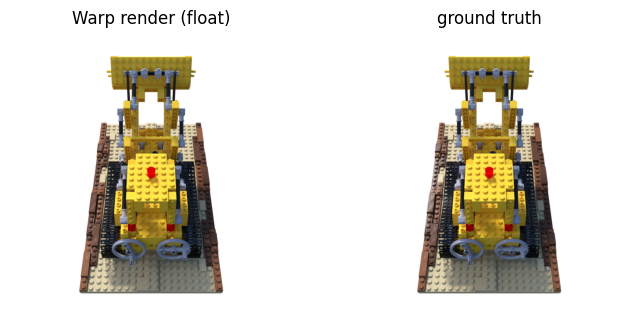

In [ ]:
def load_scene(scene, n_views=None):
    ply, data = scene_paths(scene)
    synthetic = False
    if not (os.path.exists(ply) and os.path.exists(os.path.join(data, "transforms_test.json"))):
        if not CFG["synthetic_if_missing"]:
            raise FileNotFoundError(ply)
        ply, data = f"synthetic/{scene}/point_cloud.ply", f"synthetic/{scene}/data"
        if not os.path.exists(ply): write_synthetic_scene(ply, data, seed=sum(scene.encode()))
        synthetic = True
    rs = 1.0 if synthetic else CFG["res_scale"]
    model = load_ply(ply)
    cams, gts, bg = load_split(data, "test", rs, CFG["white_bg"], max_views=n_views)
    return dict(scene=scene, ply=ply, data=data, synthetic=synthetic, res_scale=rs, model=model, cams=cams, gts=gts, bg=bg)

S = load_scene(CFG["scene"], CFG["n_eval_views"])
model0, cams, gts, BG = S["model"], S["cams"], S["gts"], S["bg"]
print(f"{S['scene']}: N={n_splats(model0):,}  SH rest K={model0['shN'].shape[1]}  views={len(cams)} @ {cams[0]['W']}x{cams[0]['H']}"
      + ("  [SYNTHETIC FALLBACK]" if S["synthetic"] else ""))
r_float = evaluate(model0, cams, gts, BG, n_views=CFG["n_sweep_views"], keep_views=[0])
print(f"float model: PSNR {r_float['psnr']:.2f} dB  ({r_float['sec_per_view']*1000:.0f} ms/view)")
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(np.clip(r_float["images"][0], 0, 1)); ax[0].set_title("Warp render (float)")
ax[1].imshow(gts[0]); ax[1].set_title("ground truth")
for a in ax: a.axis("off")
plt.show()

## 5. (Optional) importance pruning
The proposal assumes an already-pruned checkpoint. If `prune_keep` is set, splats are ranked by their accumulated blending weight
$\sum_{\text{train views, pixels}} \alpha_i T_i$ (LightGaussian-style global significance) and the top fraction is kept. All later stages use this fixed model.

In [ ]:
def importance_scores(model, data_dir, res_scale, n_views):
    tcams, _, bg = load_split(data_dir, "train", res_scale, CFG["white_bg"], max_views=n_views, load_images=False)
    if S["synthetic"]:
        for c in tcams:
            r = CFG["synth_res"]; f = 0.5 * r / math.tan(0.5 * 0.6911112070083618)
            c.update(W=r, H=r, cx=r / 2, cy=r / 2, fx=f, fy=f)
    dm = to_device(model)
    imp = wp.zeros(dm["N"], dtype=float, device=DEVICE)
    for c in tcams:
        render(dm, c, bg, importance=imp)
    return imp.numpy()

if CFG["prune_keep"]:
    imp = importance_scores(model0, S["data"], S["res_scale"], CFG["n_prune_views"])
    keep = np.argsort(-imp)[: int(CFG["prune_keep"] * len(imp))]
    model = subset(model0, np.sort(keep))       # keep original file order
    r = evaluate(model, cams, gts, BG, n_views=CFG["n_sweep_views"])
    print(f"pruned {n_splats(model0):,} -> {n_splats(model):,}: PSNR {r['psnr']:.2f} dB")
else:
    model = model0
N = n_splats(model)
W_GRID = int(math.ceil(math.sqrt(N)))
print(f"N = {N:,}  ->  grid {W_GRID} x {W_GRID}  ({W_GRID**2 - N} padding cells)")

N = 322,652  ->  grid 569 x 569  (1109 padding cells)


## 6. Fixed quantizer and the 1D entropy-coded baseline
Bit widths and ranges are computed **once per scene** and shared by every ordering / codec, so all lossless variants decode to exactly the same quantized model.

| group | channels | bits | range |
|---|---|---|---|
| means | 3 | 16 (stored as hi/lo byte images, always lossless) | per-axis min/max |
| scales | 3 (log) | 8 | **one shared** min/max (invariant to axis permutation) |
| quats | 4 (wxyz) | 8 | fixed [-1, 1] (invariant to sign / 48-form changes) |
| opacity | 1 (sigmoid) | 8 | [0, 1] |
| sh0 | 3 | 8 | per-channel min/max |
| shN | 15×3 | 8 | per-coefficient min/max (optionally percentile-clipped) |

In [ ]:
BITS = dict(means=16, scales=8, quats=8, opacity=8, sh0=8, shN=8)

class Quantizer:
    def __init__(self, m, bits=BITS, shN_clip_pct=0.0):
        self.bits = dict(bits)
        K = m["shN"].shape[1]
        shN = m["shN"].reshape(len(m["shN"]), -1)
        r = dict(means=(m["means"].min(0), m["means"].max(0)),
                 scales=(np.full(3, m["scales"].min()), np.full(3, m["scales"].max())),
                 quats=(np.full(4, -1.0), np.full(4, 1.0)),
                 opacity=(np.zeros(1), np.ones(1)),
                 sh0=(m["sh0"].min(0), m["sh0"].max(0)),
                 shN=((np.percentile(shN, shN_clip_pct, 0), np.percentile(shN, 100 - shN_clip_pct, 0)) if shN_clip_pct > 0
                      else (shN.min(0), shN.max(0))) if K else (np.zeros(0), np.zeros(0)))
        self.ranges = {k: (np.asarray(lo, np.float64), np.asarray(hi, np.float64)) for k, (lo, hi) in r.items()}
        self.K = K

    def _q(self, x, key):
        lo, hi = self.ranges[key]; L = (1 << self.bits[key]) - 1
        c = np.rint((x - lo) / np.maximum(hi - lo, 1e-12) * L)
        return np.clip(c, 0, L).astype(np.uint16 if self.bits[key] > 8 else np.uint8)

    def _dq(self, c, key):
        lo, hi = self.ranges[key]; L = (1 << self.bits[key]) - 1
        return (lo + c.astype(np.float64) / L * (hi - lo)).astype(np.float32)

    def quantize(self, m):
        n = len(m["means"])
        return dict(means=self._q(m["means"], "means"), scales=self._q(m["scales"], "scales"),
                    quats=self._q(m["quats"], "quats"), opacity=self._q(sigmoid(m["opacity"])[:, None], "opacity"),
                    sh0=self._q(m["sh0"], "sh0"), shN=self._q(m["shN"].reshape(n, -1), "shN").reshape(n, self.K, 3))

    def dequantize(self, c):
        n = len(c["means"])
        q = self._dq(c["quats"], "quats")
        nq = np.linalg.norm(q, axis=1, keepdims=True)
        q = np.where(nq > 1e-6, q / np.maximum(nq, 1e-12), np.array([1, 0, 0, 0], np.float32))
        return dict(means=self._dq(c["means"], "means"), scales=self._dq(c["scales"], "scales"), quats=q.astype(np.float32),
                    opacity=logit(self._dq(c["opacity"], "opacity")[:, 0]).astype(np.float32),
                    sh0=self._dq(c["sh0"], "sh0"),
                    shN=self._dq(c["shN"].reshape(n, -1), "shN").reshape(n, self.K, 3))

    def meta(self):
        return dict(bits=self.bits, K=self.K,
                    ranges={k: [lo.astype(np.float32).tolist(), hi.astype(np.float32).tolist()] for k, (lo, hi) in self.ranges.items()})

### Canonical rotation–scale forms (needed before quantizing)
A Gaussian's covariance $R\,S^2R^\top$ is unchanged by $R\to RP$, $s\to\sigma_P(s)$ for any of the **24 proper signed permutation matrices** $P$ (rotations of the cube),
and $q\to -q$ gives the same $R$: **48 equivalent (quaternion, scale) encodings**. Modes:
* `none` — as stored; `sign` — $w\ge0$;
* `sorted` — permute axes so $s_x\ge s_y\ge s_z$, then pick the remaining sign variant closest to identity (a deterministic per-splat canonical form);
* `neighbor` — start from `sorted`, then on the grid pick for every splat the one of 48 forms closest (L1, code space) to the mean of its 4 grid neighbours (PRAS-style, red–black Gauss–Seidel in Warp, §8).

In [ ]:
def quat_mul_np(a, b):
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2, w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2, w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], -1)

def cube_group():
    """24 proper signed permutation matrices P with quaternion q_P and scale permutation (s'_j = s[perm[j]])."""
    Ps, perms = [], []
    for perm in itertools.permutations(range(3)):
        for sg in itertools.product([1, -1], repeat=3):
            P = np.zeros((3, 3))
            for j in range(3): P[perm[j], j] = sg[j]
            if np.linalg.det(P) > 0: Ps.append(P); perms.append(perm)
    return np.stack(Ps), mat_to_quat(np.stack(Ps)), np.array(perms, np.int32)

CUBE_P, CUBE_Q, CUBE_PERM = cube_group()
assert len(CUBE_P) == 24

def check_cube_group(n=200, seed=0):
    rng = np.random.default_rng(seed)
    q = rng.normal(size=(n, 4)); s = rng.normal(size=(n, 3))
    cov = lambda q, s: (lambda R: R @ np.einsum("nj,nkj->nkj", np.exp(2 * s), R).transpose(0, 2, 1))(quat_to_mat_np(q))
    ref = cov(q, s)
    for c in range(24):
        q2 = quat_mul_np(q / np.linalg.norm(q, axis=1, keepdims=True), CUBE_Q[c][None]); s2 = s[:, CUBE_PERM[c]]
        assert np.allclose(cov(q2, s2), ref, atol=1e-9) and np.allclose(cov(-q2, s2), ref, atol=1e-9)
    return True
print("48 equivalent forms preserve covariance:", check_cube_group())

def canonicalize(m, mode):
    m = dict(m)
    q = m["quats"] / np.linalg.norm(m["quats"], axis=1, keepdims=True)
    s = m["scales"]
    if mode in ("sorted", "neighbor"):
        # candidates whose permutation sorts the scales descending; among them the one with largest |w|
        qo, so = np.empty_like(q), np.empty_like(s)
        for a in range(0, len(q), 100_000):                                   # chunked: (n,24,4) candidates
            allq = quat_mul_np(q[a:a + 100_000, None, :], CUBE_Q[None])
            alls = s[a:a + 100_000][:, CUBE_PERM]
            sorted_ok = (alls[..., 0] >= alls[..., 1]) & (alls[..., 1] >= alls[..., 2])
            best = np.where(sorted_ok, np.abs(allq[..., 0]), -1.0).argmax(1)
            r = np.arange(len(best))
            qo[a:a + 100_000], so[a:a + 100_000] = allq[r, best], alls[r, best]
        q, s = qo, so
    if mode != "none":
        q = q * np.where(q[:, :1] < 0, -1.0, 1.0)
    m["quats"], m["scales"] = q.astype(np.float32), s.astype(np.float32)
    return m

48 equivalent forms preserve covariance: True


### 1D baseline
Quantized attributes stored as one byte stream per attribute column (column-major — a *stronger* baseline than interleaved records)
and entropy-coded with general-purpose 1D coders. We report it both in the original file order and after Morton sorting (to separate "ordering" from "2D image coding").

In [ ]:
QZ = Quantizer(model, BITS, CFG["shN_clip_pct"])
model_c = canonicalize(model, "sign")
codes_1d = QZ.quantize(model_c)
model_q = QZ.dequantize(codes_1d)

def column_streams(codes, order=None):
    out = []
    for k, c in codes.items():
        c = c.reshape(len(c), -1)
        if order is not None: c = c[order]
        if c.dtype == np.uint16:
            out += [(c >> 8).astype(np.uint8).T.tobytes(), (c & 255).astype(np.uint8).T.tobytes()]
        else:
            out.append(np.ascontiguousarray(c.T).tobytes())
    return b"".join(out)

def baseline_1d(codes, order=None):
    raw = column_streams(codes, order)
    r = dict(raw=len(raw), zlib=len(zlib.compress(raw, 9)), lzma=len(lzma.compress(raw, preset=9)))
    if zstd is not None: r["zstd"] = len(zstd.ZstdCompressor(level=19).compress(raw))
    return r

ply_bytes = save_ply(model, os.path.join(CFG["out_dir"], "model_float.ply"))
b1d_file = baseline_1d(codes_1d)
print(f"float .ply: {ply_bytes/1e6:.2f} MB  ({8*ply_bytes/N:.0f} bits/splat)")
print("1D quantized (file order):", {k: f"{v/1e6:.3f} MB" for k, v in b1d_file.items()})
r_q = evaluate(model_q, cams, gts, BG, n_views=CFG["n_sweep_views"])
print(f"PSNR float {r_float['psnr']:.3f} dB | 1D-quantized {r_q['psnr']:.3f} dB")

float .ply: 80.02 MB  (1984 bits/splat)
1D quantized (file order): {'raw': '20.004 MB', 'zlib': '15.782 MB', 'lzma': '15.495 MB', 'zstd': '15.619 MB'}
PSNR float 35.862 dB | 1D-quantized 35.837 dB


## 7. Orderings → $W\times W$ grid
A permutation `perm` maps raster index → splat. The $W^2-N$ padding cells sit at the end in raster order (≤ 2 rows) and are filled by
**edge clamping** (copy of the cell above), so they cost almost nothing; the decoder keeps the first $N$ pixels.

* **unsorted**: file order.
* **morton**: 30-bit 3D Z-order codes computed in a Warp kernel + Warp stable radix sort.
* **swap**: start from Morton; each iteration tiles the grid into $b\times b$ blocks (random offset), pairs cells inside each block with a random pairing
  and swaps a pair if that lowers the L1 distance of the two cells to their 4-neighbours (neighbours frozen during the pass ⇒ fully parallel, one thread per pair).
  Block size goes coarse→fine. The sort features are normalised position, base colour, *sorted* log-scales and opacity (all invariant to the 48-form choice).
* **plas** (optional): Parallel Linear Assignment Sorting if the `plas` package is installed.

unsorted     0.00s  feature neighbour-L1 = 0.1375
morton       0.06s  feature neighbour-L1 = 0.0371
swap         1.29s  feature neighbour-L1 = 0.0208
plas        19.29s  feature neighbour-L1 = 0.0153


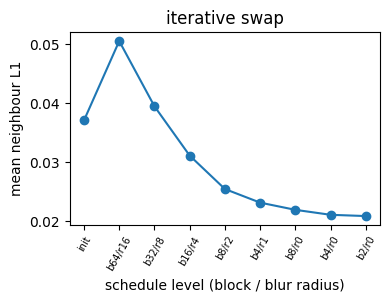

In [ ]:
@wp.func
def part1by2(v: int) -> int:
    x = v & 0x3FF
    x = (x | (x << 16)) & 0x030000FF
    x = (x | (x << 8)) & 0x0300F00F
    x = (x | (x << 4)) & 0x030C30C3
    x = (x | (x << 2)) & 0x09249249
    return x

@wp.kernel
def morton_kernel(p: wp.array(dtype=wp.vec3), lo: wp.vec3, scale: wp.vec3, codes: wp.array(dtype=int)):
    i = wp.tid()
    q = wp.cw_mul(p[i] - lo, scale)
    x = wp.clamp(int(q[0]), 0, 1023); y = wp.clamp(int(q[1]), 0, 1023); z = wp.clamp(int(q[2]), 0, 1023)
    codes[i] = part1by2(x) | (part1by2(y) << 1) | (part1by2(z) << 2)

def morton_order(means):
    n = len(means)
    lo, hi = means.min(0), means.max(0)
    sc = 1023.0 / np.maximum(hi - lo, 1e-9)
    p = wp.array(means, dtype=wp.vec3, device=DEVICE)
    keys = wp.zeros(2 * n, dtype=int, device=DEVICE)
    vals = wp.zeros(2 * n, dtype=int, device=DEVICE)
    wp.launch(morton_kernel, dim=n, inputs=[p, wp.vec3(lo), wp.vec3(sc), keys], device=DEVICE)
    wp.launch(iota_kernel, dim=n, inputs=[vals], device=DEVICE)
    wp.utils.radix_sort_pairs(keys, vals, n)
    return vals.numpy()[:n].copy()

SORT_WEIGHTS = dict(means=1.0, color=0.5, scales=0.3, opacity=0.2)

def sort_features(m, w=SORT_WEIGHTS):
    cols = [(m["means"], w["means"]), (m["sh0"] * SH_C0 + 0.5, w["color"]),
            (-np.sort(-m["scales"], 1), w["scales"]), (sigmoid(m["opacity"])[:, None], w["opacity"])]
    F = []
    for c, wt in cols:
        lo, hi = c.min(0), c.max(0)
        F.append((c - lo) / np.maximum(hi - lo, 1e-9) * wt)
    return np.concatenate(F, 1).astype(np.float32)

@wp.func
def l1_rows(F: wp.array2d(dtype=float), D: int, a: int, b: int) -> float:
    s = float(0.0)
    for d in range(D):
        s += wp.abs(F[a, d] - F[b, d])
    return s

@wp.func
def cost_at(F: wp.array2d(dtype=float), D: int, W: int, x: int, y: int, v: int, ppos: int, pval: int) -> float:
    # cost of row v placed at (x,y); the cell at index ppos holds row pval
    c = float(0.0)
    if x > 0:
        n = y * W + x - 1
        if n == ppos: n = pval
        c += l1_rows(F, D, v, n)
    if x < W - 1:
        n = y * W + x + 1
        if n == ppos: n = pval
        c += l1_rows(F, D, v, n)
    if y > 0:
        n = (y - 1) * W + x
        if n == ppos: n = pval
        c += l1_rows(F, D, v, n)
    if y < W - 1:
        n = (y + 1) * W + x
        if n == ppos: n = pval
        c += l1_rows(F, D, v, n)
    return c

@wp.kernel
def swap_decide(F: wp.array2d(dtype=float), D: int, W: int, nvalid: int, bs: int, ox: int, oy: int, nbx: int,
                pa: wp.array(dtype=int), pb: wp.array(dtype=int), P: int,
                flag: wp.array(dtype=int), ia: wp.array(dtype=int), ib: wp.array(dtype=int)):
    t = wp.tid()
    flag[t] = 0
    blk = t / P
    k = t - blk * P
    x0 = (blk % nbx) * bs - ox
    y0 = (blk / nbx) * bs - oy
    xa = x0 + pa[k] % bs; ya = y0 + pa[k] / bs
    xb = x0 + pb[k] % bs; yb = y0 + pb[k] / bs
    if xa < 0 or ya < 0 or xb < 0 or yb < 0 or xa >= W or ya >= W or xb >= W or yb >= W:
        return
    a = ya * W + xa
    b = yb * W + xb
    if a >= nvalid or b >= nvalid:
        return
    before = cost_at(F, D, W, xa, ya, a, b, b) + cost_at(F, D, W, xb, yb, b, a, a)
    after = cost_at(F, D, W, xa, ya, b, b, a) + cost_at(F, D, W, xb, yb, a, a, b)
    if after < before - 1.0e-6:
        flag[t] = 1
        ia[t] = a
        ib[t] = b

@wp.kernel
def swap_apply(F: wp.array2d(dtype=float), D: int, perm: wp.array(dtype=int),
               flag: wp.array(dtype=int), ia: wp.array(dtype=int), ib: wp.array(dtype=int)):
    t = wp.tid()
    if flag[t] == 0:
        return
    a = ia[t]; b = ib[t]
    for d in range(D):
        tmp = F[a, d]; F[a, d] = F[b, d]; F[b, d] = tmp
    ti = perm[a]; perm[a] = perm[b]; perm[b] = ti

def pad_grid(arr, W):
    """(N,...) -> (W*W,...) with edge clamping (copy of the cell above) for the padding cells."""
    n = len(arr)
    out = np.empty((W * W,) + arr.shape[1:], arr.dtype)
    out[:n] = arr
    for k in range(n, W * W):
        out[k] = out[k - W]
    return out

def neighbor_l1(grid, W, n):
    """Mean |difference| between horizontally / vertically adjacent valid cells. grid: (W*W, C)."""
    g = grid.reshape(W, W, -1).astype(np.float64)
    valid = (np.arange(W * W) < n).reshape(W, W)
    dh = np.abs(g[:, 1:] - g[:, :-1]).mean(-1)[valid[:, 1:] & valid[:, :-1]]
    dv = np.abs(g[1:] - g[:-1]).mean(-1)[valid[1:] & valid[:-1]]
    return float(np.concatenate([dh, dv]).mean())

@wp.kernel
def blur_kernel(src: wp.array2d(dtype=float), dst: wp.array2d(dtype=float), D: int, W: int, r: int, horizontal: int):
    i = wp.tid()
    x = i % W
    y = i / W
    for d in range(D):
        s = float(0.0)
        c = float(0.0)
        for k in range(-r, r + 1):
            xx = x
            yy = y
            if horizontal != 0:
                xx = x + k
            else:
                yy = y + k
            if xx >= 0 and xx < W and yy >= 0 and yy < W:
                s += src[yy * W + xx, d]
                c += 1.0
        dst[i, d] = s / c

@wp.kernel
def swap_decide_target(F: wp.array2d(dtype=float), T: wp.array2d(dtype=float), D: int, W: int, nvalid: int,
                       bs: int, ox: int, oy: int, nbx: int, pa: wp.array(dtype=int), pb: wp.array(dtype=int), P: int,
                       flag: wp.array(dtype=int), ia: wp.array(dtype=int), ib: wp.array(dtype=int)):
    t = wp.tid()
    flag[t] = 0
    blk = t / P
    k = t - blk * P
    x0 = (blk % nbx) * bs - ox
    y0 = (blk / nbx) * bs - oy
    xa = x0 + pa[k] % bs; ya = y0 + pa[k] / bs
    xb = x0 + pb[k] % bs; yb = y0 + pb[k] / bs
    if xa < 0 or ya < 0 or xb < 0 or yb < 0 or xa >= W or ya >= W or xb >= W or yb >= W:
        return
    a = ya * W + xa
    b = yb * W + xb
    if a >= nvalid or b >= nvalid:
        return
    before = float(0.0)
    after = float(0.0)
    for d in range(D):
        before += wp.abs(F[a, d] - T[a, d]) + wp.abs(F[b, d] - T[b, d])
        after += wp.abs(F[a, d] - T[b, d]) + wp.abs(F[b, d] - T[a, d])
    if after < before - 1.0e-6:
        flag[t] = 1
        ia[t] = a
        ib[t] = b

# (block size, blur radius, iterations). radius > 0: swap towards a box-blurred target (PLAS-style guidance, allows long moves);
# radius 0: the exact 4-neighbour L1 criterion of the proposal.
SWAP_SCHEDULE = [(64, 16, 48), (32, 8, 48), (16, 4, 48), (8, 2, 48), (4, 1, 32), (8, 0, 32), (4, 0, 32), (2, 0, 16)]

def swap_sort(F, init_perm, W, schedule=None, seed=0):
    """Iterative block-pair swapping on the grid. F: (N,D) features in splat order. Returns (perm, energy after each level)."""
    schedule = schedule or SWAP_SCHEDULE
    rng = np.random.default_rng(seed)
    n, D = F.shape
    Fg = wp.array(pad_grid(F[init_perm], W), dtype=float, device=DEVICE)
    Tg = wp.zeros_like(Fg); tmp = wp.zeros_like(Fg)
    perm = wp.array(np.concatenate([init_perm, np.full(W * W - n, -1)]).astype(np.int32), dtype=int, device=DEVICE)
    hist = [neighbor_l1(Fg.numpy(), W, n)]
    for bs, radius, iters in schedule:
        bs = min(bs, W)
        P = bs * bs // 2
        nb = (W + bs - 1) // bs + 1
        nthreads = nb * nb * P
        flag = wp.zeros(nthreads, dtype=int, device=DEVICE)
        ia = wp.zeros(nthreads, dtype=int, device=DEVICE); ib = wp.zeros(nthreads, dtype=int, device=DEVICE)
        for it in range(iters):
            loc = rng.permutation(bs * bs).astype(np.int32)
            pa = wp.array(loc[0::2][:P], dtype=int, device=DEVICE); pb = wp.array(loc[1::2][:P], dtype=int, device=DEVICE)
            ox, oy = (int(v) for v in rng.integers(0, bs, 2))
            if radius > 0:
                wp.launch(blur_kernel, dim=W * W, inputs=[Fg, tmp, D, W, radius, 1], device=DEVICE)
                wp.launch(blur_kernel, dim=W * W, inputs=[tmp, Tg, D, W, radius, 0], device=DEVICE)
                wp.launch(swap_decide_target, dim=nthreads, device=DEVICE,
                          inputs=[Fg, Tg, D, W, n, bs, ox, oy, nb, pa, pb, P, flag, ia, ib])
            else:
                wp.launch(swap_decide, dim=nthreads, device=DEVICE,
                          inputs=[Fg, D, W, n, bs, ox, oy, nb, pa, pb, P, flag, ia, ib])
            wp.launch(swap_apply, dim=nthreads, inputs=[Fg, D, perm, flag, ia, ib], device=DEVICE)
        hist.append(neighbor_l1(Fg.numpy(), W, n))
    return perm.numpy()[:n].copy(), hist

try:
    import torch
    from plas import sort_with_plas
    HAVE_PLAS = True
except Exception:
    HAVE_PLAS = False

def plas_order(F, W):
    n, D = F.shape
    g = torch.from_numpy(pad_grid(F, W)).reshape(W, W, D).permute(2, 0, 1).float()
    g = g.cuda() if torch.cuda.is_available() else g
    _, idx = sort_with_plas(g, improvement_break=1e-4, verbose=False)
    idx = idx.flatten().cpu().numpy()
    src = np.concatenate([np.arange(n), np.full(W * W - n, -1)])   # padding cells may move; keep only real splats
    p = src[idx]
    return p[p >= 0]

def compute_order(m, method, W):
    t0 = time.time(); info = {}
    if method == "unsorted":
        perm = np.arange(n_splats(m))
    elif method == "morton":
        perm = morton_order(m["means"])
    elif method == "swap":
        perm, info["energy"] = swap_sort(sort_features(m), morton_order(m["means"]), W)
    elif method == "plas":
        perm = plas_order(sort_features(m), W)
    else:
        raise ValueError(method)
    wp.synchronize()
    info["sec"] = time.time() - t0
    assert np.array_equal(np.sort(perm), np.arange(n_splats(m)))
    return perm, info

ORDERS = ["unsorted", "morton", "swap"] + (["plas"] if HAVE_PLAS else [])
PERMS = {o: compute_order(model, o, W_GRID) for o in ORDERS}
for o, (p, info) in PERMS.items():
    print(f"{o:9s} {info['sec']:7.2f}s  feature neighbour-L1 = {neighbor_l1(pad_grid(sort_features(model)[p], W_GRID), W_GRID, N):.4f}")
if "energy" in PERMS["swap"][1]:
    plt.figure(figsize=(4, 2.5)); plt.plot(PERMS["swap"][1]["energy"], "o-")
    plt.xticks(range(len(SWAP_SCHEDULE) + 1), ["init"] + [f"b{b}/r{r}" for b, r, _ in SWAP_SCHEDULE], rotation=60, fontsize=7)
    plt.xlabel("schedule level (block / blur radius)"); plt.ylabel("mean neighbour L1"); plt.title("iterative swap"); plt.show()

## 8. Neighbour alignment of the 48 rotation–scale forms (Warp)

In [ ]:
@wp.func
def qmul(a: wp.vec4, b: wp.vec4) -> wp.vec4:
    return wp.vec4(a[0] * b[0] - a[1] * b[1] - a[2] * b[2] - a[3] * b[3],
                   a[0] * b[1] + a[1] * b[0] + a[2] * b[3] - a[3] * b[2],
                   a[0] * b[2] - a[1] * b[3] + a[2] * b[0] + a[3] * b[1],
                   a[0] * b[3] + a[1] * b[2] - a[2] * b[1] + a[3] * b[0])

@wp.kernel
def align_kernel(Q: wp.array(dtype=wp.vec4), Sl: wp.array(dtype=wp.vec3), W: int, nvalid: int, parity: int,
                 CQ: wp.array(dtype=wp.vec4), CP: wp.array(dtype=wp.vec3i), s_lo: float, s_inv: float, ws: float):
    i = wp.tid()
    x = i % W
    y = i / W
    if i >= nvalid or (x + y) % 2 != parity:
        return
    tq = wp.vec4(0.0, 0.0, 0.0, 0.0)
    ts = wp.vec3(0.0, 0.0, 0.0)
    cnt = float(0.0)
    if x > 0 and i - 1 < nvalid:
        tq += Q[i - 1]; ts += Sl[i - 1]; cnt += 1.0
    if x < W - 1 and i + 1 < nvalid:
        tq += Q[i + 1]; ts += Sl[i + 1]; cnt += 1.0
    if y > 0:
        tq += Q[i - W]; ts += Sl[i - W]; cnt += 1.0
    if y < W - 1 and i + W < nvalid:
        tq += Q[i + W]; ts += Sl[i + W]; cnt += 1.0
    if cnt == 0.0:
        return
    tq = tq / cnt
    ts = ts / cnt
    q = Q[i]
    s = Sl[i]
    best = float(1.0e30)
    bq = q
    bs = s
    for c in range(24):
        qc = qmul(q, CQ[c])
        pc = CP[c]
        sc = wp.vec3(s[pc[0]], s[pc[1]], s[pc[2]])
        ds = (wp.abs(sc[0] - ts[0]) + wp.abs(sc[1] - ts[1]) + wp.abs(sc[2] - ts[2])) * s_inv * ws
        dp = 0.5 * (wp.abs(qc[0] - tq[0]) + wp.abs(qc[1] - tq[1]) + wp.abs(qc[2] - tq[2]) + wp.abs(qc[3] - tq[3]))
        dn = 0.5 * (wp.abs(qc[0] + tq[0]) + wp.abs(qc[1] + tq[1]) + wp.abs(qc[2] + tq[2]) + wp.abs(qc[3] + tq[3]))
        if dp + ds < best:
            best = dp + ds; bq = qc; bs = sc
        if dn + ds < best:
            best = dn + ds; bq = -qc; bs = sc
    Q[i] = bq
    Sl[i] = bs

def neighbor_align(gm, n, W, iters=8, ws=1.0):
    """In-place PRAS-style alignment on a gridded float model (W*W rows)."""
    Q = wp.array(gm["quats"], dtype=wp.vec4, device=DEVICE)
    Sl = wp.array(gm["scales"], dtype=wp.vec3, device=DEVICE)
    CQ = wp.array(CUBE_Q.astype(np.float32), dtype=wp.vec4, device=DEVICE)
    CP = wp.array(CUBE_PERM, dtype=wp.vec3i, device=DEVICE)
    lo, hi = QZ.ranges["scales"][0][0], QZ.ranges["scales"][1][0]
    for it in range(iters):
        for parity in (0, 1):
            wp.launch(align_kernel, dim=W * W, device=DEVICE,
                      inputs=[Q, Sl, W, n, parity, CQ, CP, float(lo), float(1.0 / max(hi - lo, 1e-9)), ws])
    gm = dict(gm); gm["quats"] = Q.numpy(); gm["scales"] = Sl.numpy()
    gm["quats"][n:] = pad_grid(gm["quats"][:n], W)[n:]; gm["scales"][n:] = pad_grid(gm["scales"][:n], W)[n:]
    return gm

def build_grid_model(m, perm, align, W):
    """Float model laid out on the grid (W*W rows, padded) with the chosen rotation-scale form."""
    t0 = time.time()
    mc = canonicalize(m, align)
    gm = {k: pad_grid(v[perm], W) for k, v in mc.items()}
    if align == "neighbor":
        gm = neighbor_align(gm, len(perm), W)
    return gm, time.time() - t0

## 9. Images, codecs and the container
Plane layout (every pixel = the same splat in every image): `means_hi`, `means_lo` (RGB, 16-bit split, lossless only), `scales` (RGB), `quats_xyz` (RGB) + `quats_w` (L),
`opacity` (L), `sh0` (RGB), `shN_00 … shN_14` (RGB, one per SH basis function) → **22 images** + `meta.json`.

Codecs (Pillow): `png` (lossless, max zlib), `webp_ll` (lossless WebP), `jpeg` (4:4:4 by default to avoid chroma subsampling leaking across packed attributes),
`avif` (4:4:4 for RGB, monochrome for L), `webp` (lossy, always 4:2:0), and `jxl` if `pillow-jxl-plugin` is installed.
A codec config maps **attribute group → (codec, quality)**; `means` is always lossless.

In [ ]:
GROUPS = ["means", "scales", "quats", "opacity", "sh0", "shN"]
LOSSY_GROUPS = ["scales", "quats", "opacity", "sh0", "shN"]
LOSSLESS = {"png", "webp_ll", "jxl_ll"}
try:
    import pillow_jxl  # noqa
    HAVE_JXL = True
except Exception:
    HAVE_JXL = False

def make_planes(codes):
    m = codes["means"]
    P = {"means_hi": (m >> 8).astype(np.uint8), "means_lo": (m & 255).astype(np.uint8),
         "scales": codes["scales"], "quats_xyz": codes["quats"][:, 1:4], "quats_w": codes["quats"][:, 0:1],
         "opacity": codes["opacity"], "sh0": codes["sh0"]}
    for k in range(codes["shN"].shape[1]):
        P[f"shN_{k:02d}"] = codes["shN"][:, k, :]
    return P

def plane_group(name):
    return name.split("_")[0] if not name.startswith("quats") else "quats"

def planes_to_codes(P, K):
    means = (P["means_hi"].astype(np.uint16) << 8) | P["means_lo"].astype(np.uint16)
    quats = np.concatenate([P["quats_w"], P["quats_xyz"]], 1)
    shN = np.stack([P[f"shN_{k:02d}"] for k in range(K)], 1) if K else np.zeros((len(means), 0, 3), np.uint8)
    return dict(means=means, scales=P["scales"], quats=quats, opacity=P["opacity"], sh0=P["sh0"], shN=shN)

EXT = dict(png="png", webp_ll="webp", webp="webp", jpeg="jpg", avif="avif", jxl="jxl", jxl_ll="jxl")

def encode_image(arr, codec, quality=None, subsampling="4:4:4"):
    img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")
    b = io.BytesIO()
    if codec == "png":
        img.save(b, "PNG", optimize=True, compress_level=9)
    elif codec == "webp_ll":
        img.save(b, "WEBP", lossless=True, quality=90, method=4)   # method 6 / q100 is ~50x slower for ~1% gain
    elif codec == "webp":
        img.save(b, "WEBP", quality=int(quality), method=6)
    elif codec == "jpeg":
        kw = dict(subsampling={"4:4:4": 0, "4:2:2": 1, "4:2:0": 2}[subsampling]) if img.mode == "RGB" else {}
        ImageFile.MAXBLOCK = max(ImageFile.MAXBLOCK, 4 * arr.shape[0] * arr.shape[1] * arr.shape[2] + 65536)
        img.save(b, "JPEG", quality=int(quality), optimize=True, **kw)
    elif codec == "avif":
        kw = dict(subsampling=subsampling) if img.mode == "RGB" else {}
        img.save(b, "AVIF", quality=int(quality), speed=4, **kw)
    elif codec in ("jxl", "jxl_ll"):
        img.save(b, "JXL", lossless=(codec == "jxl_ll"), quality=100 if codec == "jxl_ll" else int(quality))
    else:
        raise ValueError(codec)
    return b.getvalue()

def decode_image(data, C):
    a = np.asarray(Image.open(io.BytesIO(data)))
    if a.ndim == 2: a = a[..., None]
    if C == 1 and a.shape[-1] > 1: a = a[..., :1]
    if C == 3 and a.shape[-1] == 1: a = np.repeat(a, 3, -1)
    return a[..., :C]

def resolve_cfg(cfg, lossless_codec="png"):
    """cfg: {group: (codec, quality)}; unspecified groups -> lossless; means forced lossless."""
    full = {g: (lossless_codec, None) for g in GROUPS}
    for g, v in (cfg or {}).items():
        if g != "means": full[g] = v
    return full

def encode_scene(gm, n, W, cfg=None, lossless_codec="png", out_dir=None):
    cfg = resolve_cfg(cfg, lossless_codec)
    codes = QZ.quantize(gm)
    planes = make_planes(codes)
    blobs, t0 = {}, time.time()
    for name, arr in planes.items():
        codec, q = cfg[plane_group(name)]
        blobs[name] = (codec, encode_image(arr.reshape(W, W, -1), codec, q), arr.shape[1])
    t_enc = time.time() - t0
    meta = dict(N=int(n), W=int(W), quant=QZ.meta(),
                planes={k: dict(codec=c, file=f"{k}.{EXT[c]}", channels=ch) for k, (c, _, ch) in blobs.items()})
    meta_bytes = json.dumps(meta, separators=(",", ":")).encode()
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
        for k, (c, data, _) in blobs.items():
            open(os.path.join(out_dir, f"{k}.{EXT[c]}"), "wb").write(data)
        open(os.path.join(out_dir, "meta.json"), "wb").write(meta_bytes)
    sizes = {k: len(d) for k, (_, d, _) in blobs.items()}
    gsize = {g: sum(v for k, v in sizes.items() if plane_group(k) == g) for g in GROUPS}
    return dict(blobs=blobs, meta=meta, codes=codes, n=n, W=W, sizes=sizes, group_sizes=gsize,
                total=sum(sizes.values()) + len(meta_bytes), meta_bytes=len(meta_bytes), t_enc=t_enc)

def decode_scene(enc):
    t0 = time.time()
    W, n = enc["W"], enc["n"]
    planes = {k: decode_image(d, ch).reshape(W * W, ch)[:n] for k, (c, d, ch) in enc["blobs"].items()}
    codes = planes_to_codes(planes, QZ.K)
    m = QZ.dequantize(codes)
    return m, codes, time.time() - t0

def codes_equal(a, b, n):
    return all(np.array_equal(a[k][:n], b[k][:n]) for k in a)

## 10. Experiment A — ordering × alignment, lossless
Every combination is encoded with lossless PNG (and lossless WebP for reference), decoded, checked bit-exact against its quantized grid,
and rendered. `nbr_L1` is the mean absolute difference between adjacent pixels over all 22 planes (in 8-bit code units).

In [ ]:
ALIGNS = ["none", "sign", "sorted", "neighbor"]
GRIDS = {}
rows = []
b1d_best = min(v for k, v in b1d_file.items() if k != "raw")
for order in ORDERS:
    perm, oinfo = PERMS[order]
    for align in ALIGNS:
        gm, t_align = build_grid_model(model, perm, align, W_GRID)
        GRIDS[(order, align)] = gm
        enc = encode_scene(gm, N, W_GRID, None, "png",
                           out_dir=os.path.join(CFG["out_dir"], S["scene"], f"{order}_{align}_png") if CFG["save_images"] else None)
        enc_w = encode_scene(gm, N, W_GRID, None, "webp_ll")
        dec, dcodes, t_dec = decode_scene(enc)
        exact = codes_equal(dcodes, enc["codes"], N)
        planes = make_planes(enc["codes"])
        nl1 = np.mean([neighbor_l1(p.astype(np.float32), W_GRID, N) for p in planes.values()])
        r = evaluate(dec, cams, gts, BG, n_views=CFG["n_sweep_views"])
        rows.append(dict(order=order, align=align, total_MB=enc["total"] / 1e6, webp_ll_MB=enc_w["total"] / 1e6,
                         bits_per_splat=8 * enc["total"] / N, vs_ply=ply_bytes / enc["total"], vs_1d=b1d_best / enc["total"],
                         **{f"{g}_KB": enc["group_sizes"][g] / 1e3 for g in GROUPS},
                         nbr_L1=nl1, sort_s=oinfo["sec"], align_s=t_align, enc_s=enc["t_enc"], dec_s=t_dec,
                         exact=exact, psnr=r["psnr"]))
dfA = pd.DataFrame(rows)
dfA.to_csv(os.path.join(CFG['out_dir'], 'expA_lossless.csv'), index=False)
pd.set_option("display.width", 250, "display.precision", 3)
dfA

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


,order,align,total_MB,webp_ll_MB,bits_per_splat,vs_ply,vs_1d,means_KB,scales_KB,quats_KB,opacity_KB,sh0_KB,shN_KB,nbr_L1,sort_s,align_s,enc_s,dec_s,exact,psnr
0,unsorted,none,16.407,14.594,406.792,4.877,0.944,1917.944,935.428,1126.225,276.757,897.532,11248.998,28.697,0.004,0.070,1.379,0.380,True,35.837
1,unsorted,sign,16.408,14.594,406.820,4.877,0.944,1917.944,935.428,1127.356,276.757,897.532,11248.998,28.693,0.004,0.076,1.357,0.370,True,35.837
2,unsorted,sorted,16.389,14.576,406.347,4.883,0.945,1917.944,835.940,1207.766,276.757,897.532,11248.998,28.588,0.004,0.853,1.904,0.361,True,35.838
3,unsorted,neighbor,16.349,14.621,405.353,4.895,0.948,1917.944,865.988,1137.636,276.757,897.532,11248.998,27.951,0.004,0.791,1.342,0.508,True,35.839
4,morton,none,14.971,13.645,371.197,5.345,1.035,1252.502,858.712,1078.010,281.392,739.658,10757.024,21.849,0.059,0.128,2.384,0.364,True,35.837
5,morton,sign,14.971,13.644,371.199,5.345,1.035,1252.502,858.712,1078.082,281.392,739.658,10757.024,21.847,0.059,0.214,2.524,0.363,True,35.837
6,morton,sorted,14.992,13.656,371.709,5.338,1.034,1252.502,798.257,1159.113,281.392,739.658,10757.024,22.127,0.059,0.989,2.766,0.355,True,35.838
7,morton,neighbor,14.948,13.659,370.622,5.353,1.037,1252.502,828.221,1085.301,281.392,739.658,10757.024,21.451,0.059,0.815,2.716,0.361,True,35.839
8,swap,none,15.210,13.867,377.136,5.261,1.019,1540.301,858.392,1094.995,284.397,644.612,10784.115,18.034,1.293,0.132,1.607,0.377,True,35.837
9,swap,sign,15.210,13.867,377.134,5.261,1.019,1540.301,858.392,1094.929,284.397,644.612,10784.115,18.032,1.293,0.129,1.622,0.363,True,35.837


Reference sizes: float .ply 80.019 MB | 1D best (lzma) 15.495 MB
1D quantized, Morton order: {'raw': '20.004 MB', 'zlib': '15.061 MB', 'lzma': '14.175 MB', 'zstd': '14.888 MB'}


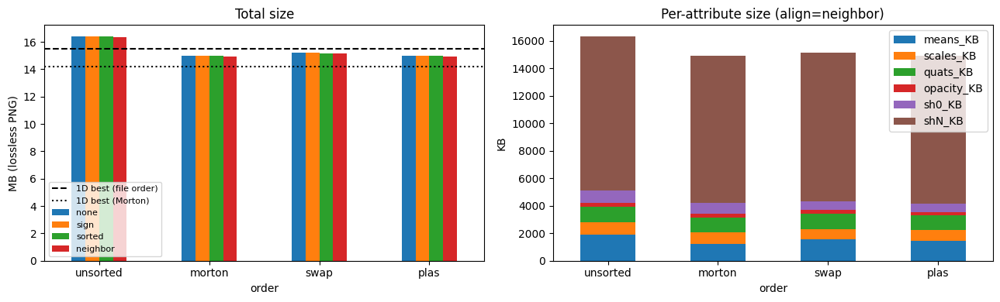

In [ ]:
print(f"Reference sizes: float .ply {ply_bytes/1e6:.3f} MB | 1D best ({min(b1d_file, key=lambda k: b1d_file[k] if k!='raw' else 1e18)}) {b1d_best/1e6:.3f} MB")
b1d_morton = baseline_1d(codes_1d, PERMS["morton"][0])
print("1D quantized, Morton order:", {k: f"{v/1e6:.3f} MB" for k, v in b1d_morton.items()})
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
piv = dfA.pivot(index="order", columns="align", values="total_MB").loc[ORDERS, ALIGNS]
piv.plot.bar(ax=ax[0], rot=0)
ax[0].axhline(b1d_best / 1e6, ls="--", c="k", label="1D best (file order)")
ax[0].axhline(min(v for k, v in b1d_morton.items() if k != "raw") / 1e6, ls=":", c="k", label="1D best (Morton)")
ax[0].set_ylabel("MB (lossless PNG)"); ax[0].legend(fontsize=8); ax[0].set_title("Total size")
best_align = dfA.groupby("align").total_MB.min().idxmin()
sub = dfA[dfA["align"] == best_align].set_index("order")[[f"{g}_KB" for g in GROUPS]]
sub.plot.bar(ax=ax[1], stacked=True, rot=0); ax[1].set_ylabel("KB"); ax[1].set_title(f"Per-attribute size (align={best_align})")
plt.tight_layout(); plt.show()

## 11. Verification: lossless round trip
Proposal requirement: lossless PNG under *any* permutation must reproduce the exact quantized tensors and the same test PSNR as the 1D-quantized model.
With `sign` alignment the quantized model is literally the same set of codes as the 1D baseline (just permuted); `sorted` / `neighbor`
re-express each Gaussian in an equivalent form, so their quantization error differs very slightly (shown as ΔPSNR).

In [ ]:
assert dfA.exact.all(), "lossless round trip failed"
for order in ORDERS:
    perm = PERMS[order][0]
    enc = encode_scene(GRIDS[(order, "sign")], N, W_GRID)
    _, dcodes, _ = decode_scene(enc)
    same = all(np.array_equal(dcodes[k], codes_1d[k].reshape(len(codes_1d[k]), *dcodes[k].shape[1:])[perm]) for k in dcodes)
    print(f"{order:9s}: decoded codes == 1D codes[perm]: {same}")
print(dfA.assign(dPSNR=dfA.psnr - r_q["psnr"])[["order", "align", "psnr", "dPSNR", "exact"]].to_string(index=False))

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


unsorted : decoded codes == 1D codes[perm]: True
morton   : decoded codes == 1D codes[perm]: True
swap     : decoded codes == 1D codes[perm]: True
plas     : decoded codes == 1D codes[perm]: True
   order    align   psnr      dPSNR  exact
unsorted     none 35.837  0.000e+00   True
unsorted     sign 35.837  0.000e+00   True
unsorted   sorted 35.838  1.405e-03   True
unsorted neighbor 35.839  1.803e-03   True
  morton     none 35.837  3.433e-06   True
  morton     sign 35.837  3.433e-06   True
  morton   sorted 35.838  1.408e-03   True
  morton neighbor 35.839  2.474e-03   True
    swap     none 35.837 -1.450e-05   True
    swap     sign 35.837 -1.450e-05   True
    swap   sorted 35.838  1.391e-03   True
    swap neighbor 35.839  1.877e-03   True
    plas     none 35.837  5.341e-06   True
    plas     sign 35.837  5.341e-06   True
    plas   sorted 35.838  1.412e-03   True
    plas neighbor 35.838  1.461e-03   True


### Visual inspection of attribute images
Note: Since `means_hi` and `means_lo` are always stored losslessly, we don't really care about them

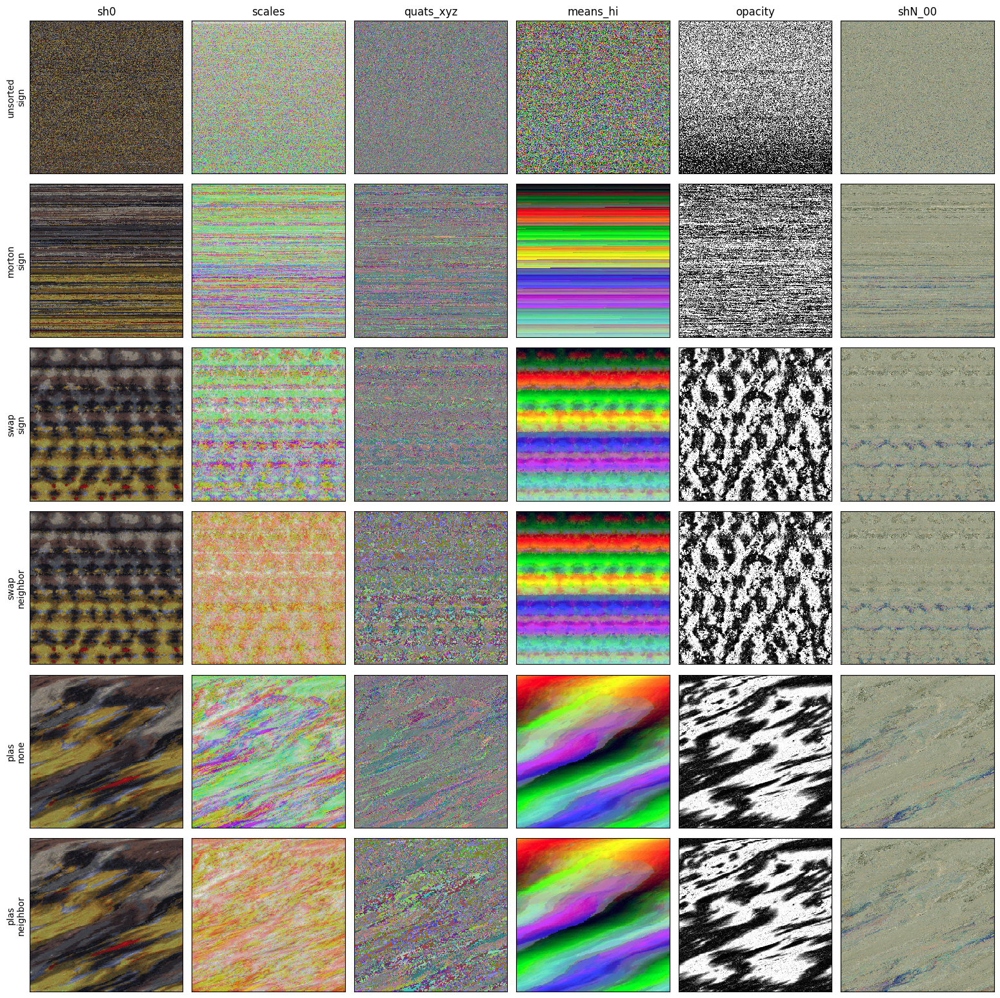

In [ ]:
def show_planes(keys, names=("sh0", "scales", "quats_xyz", "means_hi", "opacity", "shN_00")):
    fig, ax = plt.subplots(len(keys), len(names), figsize=(2.6 * len(names), 2.6 * len(keys)))
    for i, key in enumerate(keys):
        P = make_planes(QZ.quantize(GRIDS[key]))
        for j, nm in enumerate(names):
            a = P[nm].reshape(W_GRID, W_GRID, -1)
            ax[i, j].imshow(a[..., 0] if a.shape[-1] == 1 else a, cmap="gray", interpolation="nearest")
            ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
            if i == 0: ax[i, j].set_title(nm)
        ax[i, 0].set_ylabel(f"{key[0]}\n{key[1]}")
    plt.tight_layout(); plt.show()

show_planes([("unsorted", "sign"), ("morton", "sign"), ("swap", "sign"), ("swap", "neighbor"), ("plas", "none"), ("plas", "neighbor")])

## 12. Ablations for Lossy Compression under Different Sorting and Alignment Strategies

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


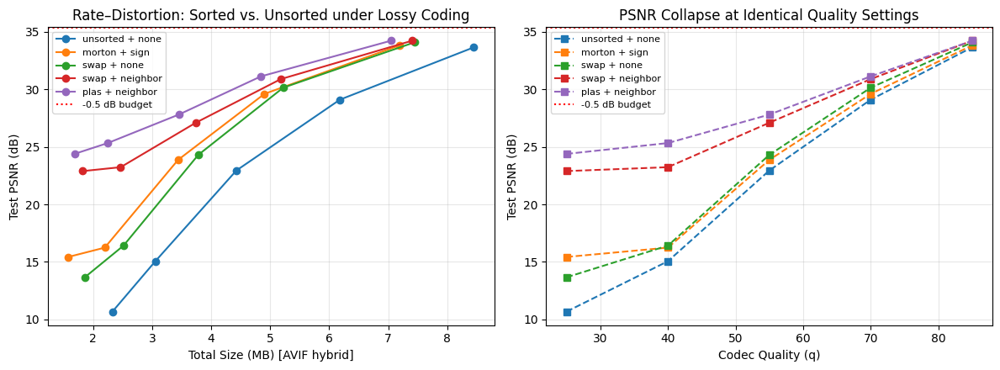

,q = 25,q = 40,q = 55,q = 70,q = 85
unsorted + none,10.68 dB (2.33 MB),15.06 dB (3.05 MB),22.95 dB (4.43 MB),29.11 dB (6.18 MB),33.66 dB (8.45 MB)
morton + sign,15.43 dB (1.58 MB),16.24 dB (2.20 MB),23.87 dB (3.44 MB),29.61 dB (4.90 MB),33.82 dB (7.19 MB)
swap + none,13.66 dB (1.86 MB),16.42 dB (2.52 MB),24.30 dB (3.78 MB),30.15 dB (5.22 MB),34.09 dB (7.44 MB)
swap + neighbor,22.90 dB (1.83 MB),23.24 dB (2.47 MB),27.10 dB (3.74 MB),30.90 dB (5.18 MB),34.23 dB (7.40 MB)
plas + neighbor,24.39 dB (1.68 MB),25.33 dB (2.25 MB),27.81 dB (3.45 MB),31.13 dB (4.84 MB),34.23 dB (7.04 MB)


In [ ]:
# === Ablation: Why Sorting & Neighbor Alignment Matter for LOSSY Compression ===
# We compare ("unsorted", "none"), ("morton", "sign"), ("swap", "none"), and ("swap", "neighbor")
# (+ ("plas", "neighbor") if available) across lossy quality levels.

ablation_pairs = [
    ("unsorted", "none"),
    ("morton", "sign"),
    ("swap", "none"),
    ("swap", "neighbor"),
] + ([("plas", "neighbor")] if HAVE_PLAS else [])

codec_to_test = "avif" if features.check("avif") else "jpeg"
qualities = [25, 40, 55, 70, 85]

rd_rows = []
for order, align in ablation_pairs:
    gm = GRIDS[(order, align)]
    for q in qualities:
        # Compress all lossy groups at q; means stays lossless PNG
        cfg = {
            "scales": (codec_to_test, q),
            "quats":  (codec_to_test, q),
            "opacity":(codec_to_test, q),
            "sh0":    (codec_to_test, q),
            "shN":    (codec_to_test, q),
        }
        enc = encode_scene(gm, N, W_GRID, cfg=cfg, lossless_codec="png")
        dec, _, _ = decode_scene(enc)
        r = evaluate(dec, cams, gts, BG, n_views=CFG["n_sweep_views"])
        rd_rows.append(dict(
            variant=f"{order} + {align}",
            order=order, align=align, q=q,
            total_MB=enc["total"] / 1e6,
            lossy_MB=(enc["total"] - enc["group_sizes"]["means"]) / 1e6,
            means_MB=enc["group_sizes"]["means"] / 1e6,
            psnr=r["psnr"],
            dPSNR=r["psnr"] - r_q["psnr"],
        ))

df_rd = pd.DataFrame(rd_rows)

# Plot Rate-Distortion curves (PSNR vs Total Size in MB)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for variant, grp in df_rd.groupby("variant", sort=False):
    ax[0].plot(grp["total_MB"], grp["psnr"], "o-", label=variant)
    ax[1].plot(grp["q"], grp["psnr"], "s--", label=variant)

ax[0].axhline(r_q["psnr"] - CFG["psnr_budget_db"], ls=":", c="r", label="-0.5 dB budget")
ax[0].set_xlabel(f"Total Size (MB) [{codec_to_test.upper()} hybrid]")
ax[0].set_ylabel("Test PSNR (dB)")
ax[0].set_title("Rate–Distortion: Sorted vs. Unsorted under Lossy Coding")
ax[0].legend(fontsize=8)
ax[0].grid(True, alpha=0.3)

ax[1].axhline(r_q["psnr"] - CFG["psnr_budget_db"], ls=":", c="r", label="-0.5 dB budget")
ax[1].set_xlabel(f"Codec Quality (q)")
ax[1].set_ylabel("Test PSNR (dB)")
ax[1].set_title("PSNR Collapse at Identical Quality Settings")
ax[1].legend(fontsize=8)
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

variant_order = ["unsorted + none", "morton + sign", "swap + none", "swap + neighbor"] + (["plas + neighbor"] if HAVE_PLAS else [])

df_clean = (
    df_rd.assign(
        summary=df_rd.apply(lambda r: f"{r['psnr']:.2f} dB ({r['total_MB']:.2f} MB)", axis=1)
    )
    .pivot(index="variant", columns="q", values="summary")
    .loc[variant_order]
    .rename_axis(index=None, columns=None)
)

df_clean.columns = [f"q = {q}" for q in df_clean.columns]
display(df_clean)

## 13. Experiment B — per-attribute lossy sensitivity
Starting from the best lossless configuration, **one group at a time** is switched to JPEG / AVIF / lossy WebP across a quality sweep while everything else stays lossless.
We log total bytes, that group's bytes, and test PSNR (sweep views).

In [ ]:
best_row = dfA.loc[dfA.total_MB.idxmin()]
BEST = (best_row["order"], best_row["align"])
GM_BEST = GRIDS[BEST]
enc_ll = encode_scene(GM_BEST, N, W_GRID)
psnr_ll = float(best_row.psnr)
print(f"best lossless: order={BEST[0]} align={BEST[1]}  {enc_ll['total']/1e6:.3f} MB  PSNR {psnr_ll:.3f}")

LOSSY_CODECS = ["jpeg", "avif", "webp"] + (["jxl"] if HAVE_JXL else [])
QUALITIES = [95, 90, 80, 70, 50, 30]
rowsB = []
for g in LOSSY_GROUPS:
    for codec in LOSSY_CODECS:
        for q in QUALITIES:
            enc = encode_scene(GM_BEST, N, W_GRID, {g: (codec, q)})
            dec, _, _ = decode_scene(enc)
            r = evaluate(dec, cams, gts, BG, n_views=CFG["n_sweep_views"])
            rowsB.append(dict(group=g, codec=codec, q=q, total_MB=enc["total"] / 1e6, group_KB=enc["group_sizes"][g] / 1e3,
                              saved_KB=(enc_ll["total"] - enc["total"]) / 1e3, psnr=r["psnr"], dpsnr=r["psnr"] - psnr_ll))
dfB = pd.DataFrame(rowsB)
dfB.to_csv(os.path.join(CFG['out_dir'], 'expB_lossy_sweep.csv'), index=False)
dfB.pivot_table(index=["group", "codec"], columns="q", values="dpsnr").round(3)

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


best lossless: order=plas align=neighbor  14.923 MB  PSNR 35.838


q                  30      50      70      80      90      95
group   codec                                                
opacity avif   -0.402  -0.092  -0.018  -0.009  -0.003  -0.001
        jpeg   -0.568  -0.427  -0.253  -0.141  -0.043  -0.010
        webp   -0.277  -0.151  -0.081  -0.044  -0.011  -0.004
quats   avif   -8.888  -4.556  -1.642  -0.933  -0.263  -0.133
        jpeg  -10.999 -10.386  -9.317  -7.834  -4.170  -1.480
        webp  -11.352 -11.017 -10.852 -10.726 -10.566 -10.521
scales  avif   -8.235  -8.688  -2.925  -1.428  -0.368  -0.173
        jpeg  -11.844 -11.656 -14.148 -15.271 -11.243  -2.718
        webp  -11.981 -11.368 -11.063  -9.990  -8.657  -8.514
sh0     avif   -4.047  -2.318  -0.930  -0.560  -0.199  -0.093
        jpeg   -3.299  -2.708  -2.270  -1.932  -1.353  -0.724
        webp   -4.558  -3.701  -3.188  -2.594  -1.871  -1.670
shN     avif   -2.355  -0.964  -0.350  -0.210  -0.074  -0.035
        jpeg   -2.482  -2.103  -1.694  -1.325  -0.737  -0.321
        webp   -1.978  -1.494  -1.202  -0.944  -0.663  -0.589

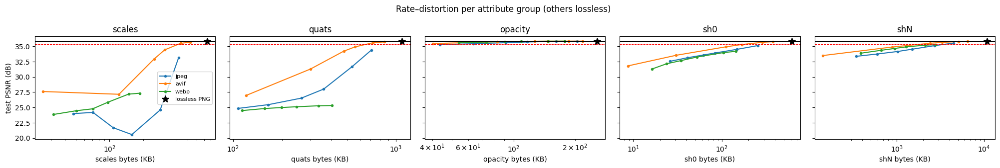

max_saved_KB_within_0p1dB  dpsnr_at_q50  dpsnr_at_q90
group   codec                                                       
opacity avif                     172.960        -0.092        -0.003
        jpeg                      94.704        -0.427        -0.043
        webp                     165.580        -0.151        -0.011
quats   avif                         NaN        -4.556        -0.263
        jpeg                         NaN       -10.386        -4.170
        webp                         NaN       -11.017       -10.566
scales  avif                         NaN        -8.688        -0.368
        jpeg                         NaN       -11.656       -11.243
        webp                         NaN       -11.368        -8.657
sh0     avif                     240.137        -2.318        -0.199
        jpeg                         NaN        -2.708        -1.353
        webp                         NaN        -3.701        -1.871
shN     avif                    5643.030        -0.964        -0.074
        jpeg                         NaN        -2.103        -0.737
        webp                         NaN        -1.494        -0.663

In [ ]:
fig, ax = plt.subplots(1, len(LOSSY_GROUPS), figsize=(4 * len(LOSSY_GROUPS), 3.4), sharey=True)
for a, g in zip(ax, LOSSY_GROUPS):
    for codec in LOSSY_CODECS:
        d = dfB[(dfB.group == g) & (dfB.codec == codec)].sort_values("group_KB")
        a.plot(d.group_KB, d.psnr, "o-", label=codec, ms=3)
    a.axhline(psnr_ll, c="k", lw=0.8); a.axhline(psnr_ll - CFG["psnr_budget_db"], c="r", ls="--", lw=0.8)
    a.plot(enc_ll["group_sizes"][g] / 1e3, psnr_ll, "k*", ms=10, label="lossless PNG")
    a.set_title(g); a.set_xlabel(f"{g} bytes (KB)"); a.set_xscale("log")
ax[0].set_ylabel("test PSNR (dB)"); ax[0].legend(fontsize=8)
plt.suptitle("Rate–distortion per attribute group (others lossless)"); plt.tight_layout(); plt.show()

# sensitivity: dB lost per KB saved, at the quality where each codec first stays within 0.1 dB
sens = (dfB.assign(db_per_100KB=-dfB.dpsnr / np.maximum(dfB.saved_KB, 1e-3) * 100)
            .groupby(["group", "codec"]).apply(lambda d: pd.Series(dict(
                max_saved_KB_within_0p1dB=d[d.dpsnr > -0.1].saved_KB.max(),
                dpsnr_at_q50=d[d.q == 50].dpsnr.mean(), dpsnr_at_q90=d[d.q == 90].dpsnr.mean())), include_groups=False))
sens

### JPEG vs AVIF at equal size
For each group, PSNR of the two codecs is interpolated at common group sizes (within the overlapping range of their RD curves).

In [ ]:
def psnr_at_size(d, sizes):
    d = d.sort_values("group_KB")
    return np.interp(sizes, d.group_KB.values, d.psnr.values, left=np.nan, right=np.nan)

cmp_rows = []
for g in LOSSY_GROUPS:
    dj, da = dfB[(dfB.group == g) & (dfB.codec == "jpeg")], dfB[(dfB.group == g) & (dfB.codec == "avif")]
    lo, hi = max(dj.group_KB.min(), da.group_KB.min()), min(dj.group_KB.max(), da.group_KB.max())
    if lo >= hi:
        cmp_rows.append(dict(group=g, note="no overlap", jpeg_range=f"{dj.group_KB.min():.0f}-{dj.group_KB.max():.0f}KB",
                             avif_range=f"{da.group_KB.min():.0f}-{da.group_KB.max():.0f}KB")); continue
    sizes = np.linspace(lo, hi, 5)
    pj, pa = psnr_at_size(dj, sizes), psnr_at_size(da, sizes)
    cmp_rows.append(dict(group=g, size_range_KB=f"{lo:.0f}-{hi:.0f}", mean_avif_minus_jpeg_dB=float(np.nanmean(pa - pj))))
pd.DataFrame(cmp_rows)

,group,size_range_KB,mean_avif_minus_jpeg_dB
0,scales,47-415,5.840
1,quats,120-706,2.791
2,opacity,44-205,0.109
3,sh0,26-256,0.573
4,shN,344-4449,0.452


## 14. Experiment C — best hybrid within the PSNR budget
Options per group = {lossless} ∪ all (codec, quality) points from Exp. B. Assuming per-group losses are roughly additive, a small multiple-choice knapsack
(DP over 0.005 dB bins) maximises bytes saved subject to $\sum \Delta\text{PSNR} \le$ budget. The chosen combination is then **actually encoded and evaluated**;
if the measured loss exceeds the budget (errors are not perfectly additive), the internal budget is shrunk and the search repeated.

In [ ]:
def knapsack(dfB, budget, step=0.005):
    nb = int(round(budget / step))
    best = {0: (0.0, {})}                                     # cost-bin -> (saved, choice)
    for g in LOSSY_GROUPS:
        opts = [(0, 0.0, None)] + [(int(math.ceil(max(-r.dpsnr, 0) / step)), r.saved_KB, (r.codec, int(r.q)))
                                   for r in dfB[dfB.group == g].itertuples() if r.saved_KB > 0]
        nxt = {}
        for c, (sv, ch) in best.items():
            for oc, osv, o in opts:
                cc = c + oc
                if cc > nb: continue
                if cc not in nxt or nxt[cc][0] < sv + osv:
                    nxt[cc] = (sv + osv, {**ch, **({g: o} if o else {})})
        best = nxt
    return max(best.values(), key=lambda t: t[0])

# The 0.5 dB budget is measured against the 1D-quantized model (the proposal's reference), so any loss already
# incurred by the lossless configuration (e.g. re-quantizing an equivalent rotation form) is subtracted first.
ref_psnr = r_q["psnr"]
budget, HYBRID = CFG["psnr_budget_db"] - max(ref_psnr - psnr_ll, 0.0), None
for attempt in range(8):
    if budget <= 0: break
    pred_saved, cfg = knapsack(dfB, budget)
    enc = encode_scene(GM_BEST, N, W_GRID, cfg)
    dec, _, _ = decode_scene(enc)
    r = evaluate(dec, cams, gts, BG, n_views=CFG["n_sweep_views"])
    print(f"internal budget {budget:.3f} dB -> {cfg}  size {enc['total']/1e6:.3f} MB  "
          f"ΔPSNR vs lossless {r['psnr']-psnr_ll:+.3f} dB, vs 1D-quantized {r['psnr']-ref_psnr:+.3f} dB")
    if r["psnr"] - ref_psnr >= -CFG["psnr_budget_db"]:
        HYBRID = cfg; break
    budget *= 0.75
HYBRID = HYBRID or {}

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


internal budget 0.500 dB -> {'opacity': ('webp', 80), 'sh0': ('avif', 95), 'shN': ('avif', 70)}  size 6.198 MB  ΔPSNR vs lossless -0.470 dB, vs 1D-quantized -0.469 dB


In [ ]:
configs = {
    "float .ply": None,
    "1D quantized": None,
    "2D unsorted (PNG)": (("unsorted", "sign"), None),
    "2D Morton (PNG)": (("morton", "sign"), None),
    f"2D best lossless {BEST}": (BEST, None),
    f"2D hybrid {HYBRID}": (BEST, HYBRID),
}
FIG_NAMES = ["float .ply", f"2D best lossless {BEST}", f"2D hybrid {HYBRID}"]
final_rows, per_view_psnr, fig_models = [], {}, {}       # keep per-view PSNR, not images (RAM)
for name, spec in configs.items():
    if name == "float .ply":
        m, size = model, ply_bytes
    elif name == "1D quantized":
        m, size = model_q, b1d_best
    else:
        key, cfg = spec
        enc = encode_scene(GRIDS[key], N, W_GRID, cfg,
                           out_dir=os.path.join(CFG["out_dir"], S["scene"], "final_" + "_".join(key) + ("_hybrid" if cfg else "")) if CFG["save_images"] else None)
        m, _, _ = decode_scene(enc); size = enc["total"]
    r = evaluate(m, cams, gts, BG, n_views=None, full=True)
    per_view_psnr[name] = np.array(r["psnr_per_view"])
    if name in FIG_NAMES: fig_models[name] = m          # decoded models are small next to 200 rendered views
    final_rows.append(dict(config=name, MB=size / 1e6, bits_per_splat=8 * size / N, ratio_vs_ply=ply_bytes / size,
                           ratio_vs_1d=b1d_best / size, psnr=r["psnr"], ssim=r["ssim"], lpips=r["lpips"]))
dfC = pd.DataFrame(final_rows)
dfC.to_csv(os.path.join(CFG['out_dir'], 'expC_final.csv'), index=False)
dfC

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


,config,MB,bits_per_splat,ratio_vs_ply,ratio_vs_1d,psnr,ssim,lpips
0,float .ply,80.019,1984.038,1.000,0.194,35.758,0.983,0.019
1,1D quantized,15.495,384.193,5.164,1.000,35.733,0.983,0.019
2,2D unsorted (PNG),16.408,406.820,4.877,0.944,35.733,0.983,0.019
3,2D Morton (PNG),14.971,371.199,5.345,1.035,35.733,0.983,0.019
4,"2D best lossless ('plas', 'neighbor')",14.923,370.003,5.362,1.038,35.734,0.983,0.019
5,"2D hybrid {'opacity': ('webp', 80), 'sh0': ('a...",6.198,153.675,12.911,2.500,35.272,0.980,0.023


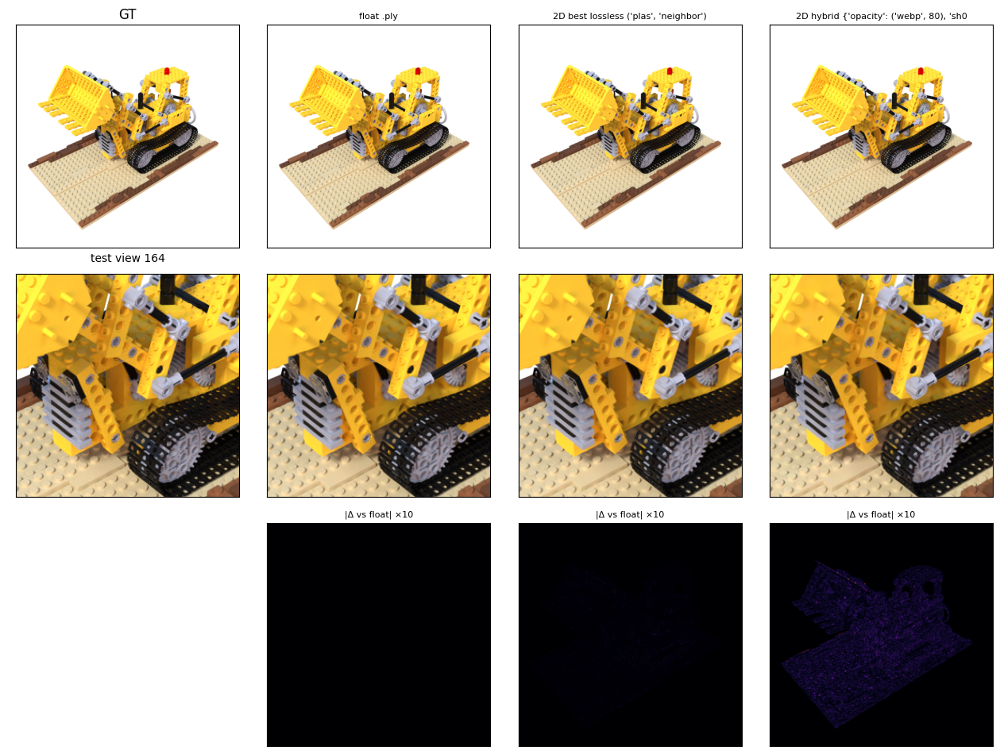

In [ ]:
# side-by-side views with zoomed crops and error maps
# show the test view where the hybrid loses the most PSNR relative to the float model; re-render only that view
vi = int(np.argmax(per_view_psnr["float .ply"] - per_view_psnr[f"2D hybrid {HYBRID}"]))
names = FIG_NAMES
view_imgs = {nm: render(to_device(fig_models[nm]), cams[vi], BG)[0] for nm in names}
H_ = gts[vi].shape[0]; c0, c1 = H_ // 3, H_ // 3 + H_ // 3
fig, ax = plt.subplots(3, len(names) + 1, figsize=(3.2 * (len(names) + 1), 9.6))
ax[0, 0].imshow(gts[vi]); ax[0, 0].set_title("GT"); ax[1, 0].imshow(gts[vi][c0:c1, c0:c1]); ax[2, 0].axis("off")
for j, nm in enumerate(names, 1):
    im = np.clip(view_imgs[nm], 0, 1)
    ax[0, j].imshow(im); ax[0, j].set_title(nm[:40], fontsize=8)
    ax[1, j].imshow(im[c0:c1, c0:c1])
    ax[2, j].imshow(np.abs(im - np.clip(view_imgs["float .ply"], 0, 1)).mean(-1) * 10, cmap="inferno", vmin=0, vmax=1)
    ax[2, j].set_title("|Δ vs float| ×10", fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_xlabel(f"test view {vi}")
plt.tight_layout(); plt.show()
del view_imgs, fig_models

## 15. Experiment D — wall-clock vs splat count

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


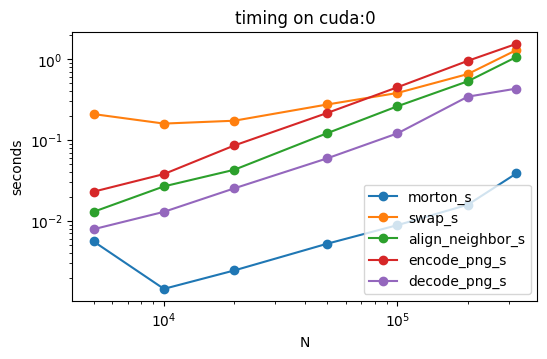

,N,morton_s,swap_s,align_neighbor_s,encode_png_s,decode_png_s
0,5000,0.006,0.209,0.013,0.023,0.008
1,10000,0.001,0.159,0.027,0.038,0.013
2,20000,0.002,0.173,0.043,0.085,0.025
3,50000,0.005,0.274,0.121,0.216,0.059
4,100000,0.009,0.381,0.261,0.448,0.121
5,200000,0.016,0.652,0.531,0.950,0.343
6,322652,0.039,1.290,1.058,1.539,0.431


In [ ]:
rowsD = []
rng = np.random.default_rng(0)
for n in sorted({x for x in [5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000] if x <= N} | {N}):
    m = subset(model, np.sort(rng.choice(N, n, replace=False)))
    Wn = int(math.ceil(math.sqrt(n)))
    t = {}
    t0 = time.time(); pm = morton_order(m["means"]); wp.synchronize(); t["morton_s"] = time.time() - t0
    t0 = time.time(); ps, _ = swap_sort(sort_features(m), pm, Wn); wp.synchronize(); t["swap_s"] = time.time() - t0
    gm, t["align_neighbor_s"] = build_grid_model(m, ps, "neighbor", Wn)
    enc = encode_scene(gm, n, Wn); t["encode_png_s"] = enc["t_enc"]
    _, _, t["decode_png_s"] = decode_scene(enc)
    rowsD.append(dict(N=n, **t))
dfD = pd.DataFrame(rowsD)
dfD.to_csv(os.path.join(CFG['out_dir'], 'expD_timing.csv'), index=False)
ax = dfD.set_index("N").plot(logx=True, logy=True, marker="o", figsize=(6, 3.5)); ax.set_ylabel("seconds")
plt.title(f"timing on {DEVICE}"); plt.show()
dfD

## 16. All three scenes
Run the condensed pipeline (1D baseline, unsorted / Morton / best-lossless 2D, and the Lego hybrid configuration re-verified per scene) on Lego, Materials and Ship.
Scenes without data are skipped (or replaced by the synthetic fallback if it is enabled).

In [ ]:
def run_scene(scene, hybrid_cfg, order=BEST[0], align=BEST[1]):
    global QZ
    Sx = load_scene(scene, CFG["n_eval_views"])
    m = Sx["model"]
    if CFG["prune_keep"]:
        imp = importance_scores(m, Sx["data"], Sx["res_scale"], CFG["n_prune_views"])
        m = subset(m, np.sort(np.argsort(-imp)[: int(CFG["prune_keep"] * len(imp))]))
    n = n_splats(m); Wn = int(math.ceil(math.sqrt(n)))
    QZ = Quantizer(m, BITS, CFG["shN_clip_pct"])
    c1d = QZ.quantize(canonicalize(m, "sign"))
    out = []
    ply_b = save_ply(m, os.path.join(CFG["out_dir"], f"{scene}_float.ply"))
    r = evaluate(QZ.dequantize(c1d), Sx["cams"], Sx["gts"], Sx["bg"], full=True)
    b1 = min(v for k, v in baseline_1d(c1d).items() if k != "raw")
    out.append(dict(scene=scene, config="1D quantized", MB=b1 / 1e6, ratio_vs_ply=ply_b / b1, **{k: r[k] for k in ("psnr", "ssim", "lpips")}))
    perms = {"unsorted": np.arange(n), "morton": morton_order(m["means"])}
    perms[order] = perms.get(order) if order in perms else compute_order(m, order, Wn)[0]
    for label, o, a, cfg in [("2D unsorted", "unsorted", "sign", None), ("2D Morton", "morton", "sign", None),
                             (f"2D {order}/{align}", order, align, None), (f"2D {order}/{align} + hybrid", order, align, hybrid_cfg)]:
        gm, _ = build_grid_model(m, perms[o], a, Wn)
        enc = encode_scene(gm, n, Wn, cfg)
        dec, _, _ = decode_scene(enc)
        r = evaluate(dec, Sx["cams"], Sx["gts"], Sx["bg"], full=True)
        out.append(dict(scene=scene, config=label, MB=enc["total"] / 1e6, ratio_vs_ply=ply_b / enc["total"],
                        **{k: r[k] for k in ("psnr", "ssim", "lpips")}))
    df = pd.DataFrame(out)
    df["ratio_vs_1d"] = df.MB.iloc[0] / df.MB
    df["dpsnr_vs_1d"] = df.psnr - df.psnr.iloc[0]
    return df

QZ_main = QZ
dfE = pd.concat([run_scene(s, HYBRID) for s in CFG["scenes"]], ignore_index=True)
QZ = QZ_main
dfE.to_csv(os.path.join(CFG['out_dir'], 'expE_scenes.csv'), index=False)
dfE

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")
/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")
/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


,scene,config,MB,ratio_vs_ply,psnr,ssim,lpips,ratio_vs_1d,dpsnr_vs_1d
0,lego,1D quantized,15.495,5.164,35.733,0.983,0.019,1.000,0.000e+00
1,lego,2D unsorted,16.408,4.877,35.733,0.983,0.019,0.944,0.000e+00
2,lego,2D Morton,14.971,5.345,35.733,0.983,0.019,1.035,-9.384e-06
3,lego,2D plas/neighbor,14.910,5.367,35.734,0.983,0.019,1.039,1.180e-03
4,lego,2D plas/neighbor + hybrid,6.196,12.914,35.265,0.980,0.023,2.501,-4.681e-01
5,materials,1D quantized,13.781,5.145,30.013,0.960,0.044,1.000,0.000e+00
6,materials,2D unsorted,14.594,4.859,30.013,0.960,0.044,0.944,0.000e+00
7,materials,2D Morton,13.088,5.418,30.013,0.960,0.044,1.053,-3.815e-06
8,materials,2D plas/neighbor,12.965,5.469,30.012,0.960,0.044,1.063,-3.165e-04
9,materials,2D plas/neighbor + hybrid,4.794,14.790,29.834,0.957,0.052,2.874,-1.790e-01


Render the ship scene across different methods

/tmp/ipykernel_512/392142064.py:31: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(arr[..., 0] if arr.shape[-1] == 1 else arr, "L" if arr.shape[-1] == 1 else "RGB")


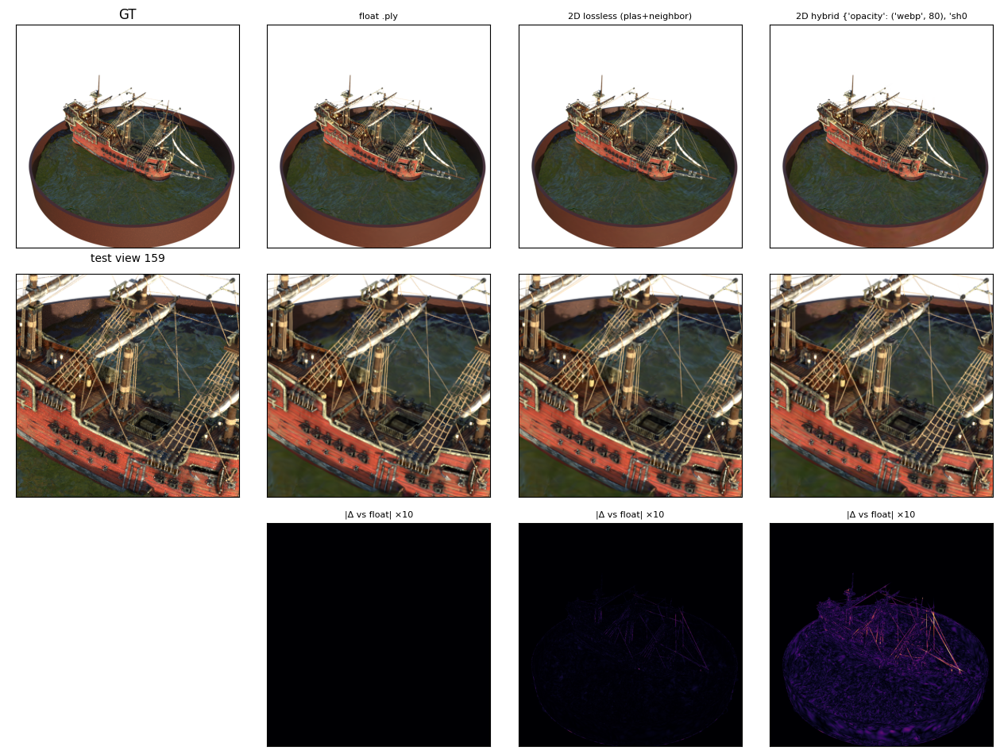

In [ ]:
# side-by-side views with zoomed crops and error maps for "ship"
# show the test view where the hybrid loses the most PSNR relative to the float model; re-render only that view
S_ship = load_scene("ship", CFG["n_eval_views"])
m_ship, cams_ship, gts_ship, bg_ship = S_ship["model"], S_ship["cams"], S_ship["gts"], S_ship["bg"]
N_ship = n_splats(m_ship)
W_ship = int(math.ceil(math.sqrt(N_ship)))

_prev_QZ = QZ
QZ = Quantizer(m_ship, BITS, CFG["shN_clip_pct"])

best_order_ship = "plas" if HAVE_PLAS else "swap"
best_align_ship = "neighbor"
perm_ship, _ = compute_order(m_ship, best_order_ship, W_ship)
gm_ship, _ = build_grid_model(m_ship, perm_ship, best_align_ship, W_ship)

enc_ship_ll  = encode_scene(gm_ship, N_ship, W_ship, None, "png")
dec_ship_ll, _, _ = decode_scene(enc_ship_ll)

enc_ship_hyb = encode_scene(gm_ship, N_ship, W_ship, HYBRID, "png")
dec_ship_hyb, _, _ = decode_scene(enc_ship_hyb)
QZ = _prev_QZ

ship_fig_models = {
    "float .ply": m_ship,
    f"2D lossless ({best_order_ship}+{best_align_ship})": dec_ship_ll,
    f"2D hybrid {HYBRID}": dec_ship_hyb,
}
ship_names = list(ship_fig_models.keys())

# Find the worst-case test view (largest PSNR drop between float .ply and 2D hybrid)
r_ship_float = evaluate(m_ship, cams_ship, gts_ship, bg_ship)
r_ship_hyb   = evaluate(dec_ship_hyb, cams_ship, gts_ship, bg_ship)
vi = int(np.argmax(np.array(r_ship_float["psnr_per_view"]) - np.array(r_ship_hyb["psnr_per_view"])))

view_imgs = {nm: render(to_device(ship_fig_models[nm]), cams_ship[vi], bg_ship)[0] for nm in ship_names}
H_ = gts_ship[vi].shape[0]; c0, c1 = H_ // 3, H_ // 3 + H_ // 3
fig, ax = plt.subplots(3, len(ship_names) + 1, figsize=(3.2 * (len(ship_names) + 1), 9.6))
ax[0, 0].imshow(gts_ship[vi]); ax[0, 0].set_title("GT"); ax[1, 0].imshow(gts_ship[vi][c0:c1, c0:c1]); ax[2, 0].axis("off")
for j, nm in enumerate(ship_names, 1):
    im = np.clip(view_imgs[nm], 0, 1)
    ax[0, j].imshow(im); ax[0, j].set_title(nm[:40], fontsize=8)
    ax[1, j].imshow(im[c0:c1, c0:c1])
    ax[2, j].imshow(np.abs(im - np.clip(view_imgs["float .ply"], 0, 1)).mean(-1) * 10, cmap="inferno", vmin=0, vmax=1)
    ax[2, j].set_title("|Δ vs float| ×10", fontsize=8)
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
ax[0, 0].set_xlabel(f"test view {vi}")
plt.tight_layout(); plt.show()
del view_imgs, ship_fig_models